# Reasoning in Large Language Models: From First Principles to Research Practice
### An executable textbook for Google Colab • Kishore's AI learning series

**Audience:** a curious beginner who is willing to work towards the mathematics. **Scope:** reasoning definitions, neural computation, a complete tiny causal Transformer, supervised training, inference-time search, verification, reinforcement learning, evaluation, limitations, and research methods.

You will build the foundations instead of being asked to accept unexplained equations. Every substantial equation is accompanied by its symbols, meaning, and a numerical or executable example. The central question is: **what can a learned system do to solve a problem, and what evidence would justify calling that reasoning?**

This is a substantial study notebook, not a single-session tutorial. Use the milestones below. Allow several study sessions; the default experiments are deliberately small. Timings depend on your machine. No paid service, credentials, external dataset, downloaded model, or GPU is required. All normal code uses Python, NumPy, and Matplotlib, which are normally available in Colab.

**How to use in Colab:** upload this `.ipynb` through **File → Upload notebook**. Choose a standard Python runtime; CPU is sufficient. Run cells in order, or use **Runtime → Run all**. If you edit definitions, rerun dependent cells. Embedded outputs are a record of one authoring run, not guaranteed results on every platform.

**Scientific boundary:** this notebook explains mechanisms and implements miniature experiments. It does not reproduce frontier reasoning, prove that models think like humans, or reveal proprietary training details. A synthetic task is a controlled learning exercise, not a substitute for evaluation on real work. Research references use original papers and official reports; historical milestones are dated, not leaderboard claims.


## Learning map

| Part | Chapters | You should be able to do afterwards |
|---|---|---|
| Foundations | 1–5 | Define reasoning, manipulate probabilities, read vectors and derivatives |
| Neural mechanics | 6–11 | Explain tokens, attention, scratchpads, loss, and backpropagation |
| Build a model | 12–16 | Train and evaluate a complete miniature decoder Transformer |
| Inference systems | 17–20 | Implement voting, search, checking, and compute-budget comparisons |
| Learning to reason | 21–25 | Derive policy gradients, understand PPO/GRPO, run a reward-learning experiment |
| Scientific evaluation | 26–30 | Measure robustness, calibration, faithfulness, and draw bounded conclusions |
| Research and practice | 31–35 | Navigate latent reasoning, hard problems, projects, references, and exercises |

**Suggested passes:** first read the prose and run the cells; second rederive the equations with a pencil; third modify one experiment at a time. The tiny automatic-differentiation engine is deliberately included so that "backpropagation happens here" is not a black box.

**Milestone A:** explain why the conclusion of a deduction can be valid but factually wrong. **B:** trace a token from embedding to loss. **C:** distinguish teacher-forced loss from free-generation accuracy. **D:** distinguish pass@k from deployable answer selection. **E:** explain exactly what reward training can and cannot establish.


In [1]:
import sys, math, time, json, random, itertools, re
from collections import Counter, deque
from dataclasses import dataclass
import numpy as np
import matplotlib.pyplot as plt
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=4, suppress=True)
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__)
print('CPU-only core; no downloads or external calls.')


Python: 3.12.14 | NumPy: 2.3.5
CPU-only core; no downloads or external calls.


## 1. What reasoning means—and what this notebook will measure

A useful **operational definition** is the application of information, rules, or constraints to derive conclusions, compare explanations, or construct actions towards a goal. Operational means that it helps design observations and tests. It is not a universally agreed definition of a mental phenomenon.

**Deduction:** if all approved transfers have passed check A, and transfer X is approved, X has passed A. The inference preserves truth **if** the premises are true. **Induction:** repeated observations suggest a general rule; the rule can be overturned by new evidence. **Abduction:** infer a plausible explanation, such as a network failure behind several declined transactions. Plausibility is not certainty. **Planning:** find a sequence that reaches a target under rules. **Analogical reasoning:** transfer a relational pattern between situations. **Causal reasoning:** reason about interventions, requiring assumptions beyond observed correlations.

Do not collapse these into a single score. A model may be strong at coding and weak at causal identification. Nor does a reasoning result settle consciousness, understanding in every philosophical sense, or free will.

A useful distinction is **behaviour**, **mechanism**, and **interpretation**. Behaviour: an answer is right. Mechanism: a particular internal computation caused it. Interpretation: we decide whether to describe that computation as reasoning. One successful example settles none of the broad questions by itself.


In [2]:
def forward_chain(facts, rules):
    facts = set(facts)
    proofs = {f: ('given',) for f in facts}
    changed = True
    while changed:
        changed = False
        for premises, conclusion in rules:
            if set(premises) <= facts and conclusion not in facts:
                facts.add(conclusion)
                proofs[conclusion] = tuple(premises)
                changed = True
    return facts, proofs
facts, proofs = forward_chain(
    {'amount_above_1000', 'identity_checked'},
    [({'amount_above_1000'}, 'extra_approval_required'),
     ({'extra_approval_required', 'identity_checked'}, 'send_for_review')])
print(sorted(facts))
print('Evidence for send_for_review:', proofs['send_for_review'])
assert 'send_for_review' in facts


['amount_above_1000', 'extra_approval_required', 'identity_checked', 'send_for_review']
Evidence for send_for_review: ('identity_checked', 'extra_approval_required')


### Why start with a symbolic program?

The program explicitly stores facts and rules. Its intermediate steps are inspectable, and we can explain exactly why a conclusion followed. An LLM generally represents useful structure in distributed numerical activations and learned parameters instead. Both can produce the same answer without implementing the same algorithm.

Even this rule engine assumes its initial facts are correct and its rules faithfully describe the task. A sound deduction from a bad business rule still gives an unsuitable real-world action. **Correct inference and correct premises are separate requirements.**

A serious evaluation should test novel instances, alternative phrasings, distracting information, harder compositions, valid counterexamples, and missing information. The goal is to distinguish stable methods from accidental success—not to assume all failures establish that reasoning never occurs.

## 2. Probability from the beginning

A probability assigns a number between 0 and 1 to an event under a model of uncertainty. Mutually exclusive and exhaustive outcomes have probabilities summing to 1. A conditional probability $P(A\mid B)$ means the probability of A when B is known.

The multiplication rule is
$$P(A,B)=P(A\mid B)P(B).$$
Here $P(A,B)$ is the probability that both occur. This is not an independence assumption. Independence is the additional claim $P(A\mid B)=P(A)$.

For a sequence $y_1,\ldots,y_T$ and input $x$, repeated multiplication gives
$$P(y_1,\ldots,y_T\mid x)=\prod_{t=1}^{T}P(y_t\mid x,y_1,\ldots,y_{t-1}).$$
$T$ is sequence length and $t$ indexes a position. The product symbol $\prod$ says "multiply all terms." This identity underlies autoregressive language models: each token is conditioned on the input and previous tokens.

**Worked example:** if the probability of selecting a correct first step is 0.8 and the conditional probability of a correct second step given that first step is 0.9, this particular two-step correct path has probability $0.8\times0.9=0.72$. Other correct paths may exist; their probabilities must also be counted when computing total success.


In [3]:
path_probs = np.array([0.8, 0.9, 0.7])
print('Probability of this path:', path_probs.prod())
print('Log probability of path:', np.log(path_probs).sum())
assert np.isclose(np.exp(np.log(path_probs).sum()), path_probs.prod())


Probability of this path: 0.504
Log probability of path: -0.6851790109107685


### Bayes' rule and uncertain explanations

Bayes' rule reverses a conditional:
$$P(H\mid E)=\frac{P(E\mid H)P(H)}{P(E)}.$$
$H$ is a hypothesis, $E$ is observed evidence, $P(H)$ is the prior, $P(E\mid H)$ is the likelihood, and $P(H\mid E)$ is the posterior. $P(E)$ normalises the probabilities. The rule follows by writing $P(H,E)$ in both orders and equating them.

Suppose 1% of transactions are fraudulent. A detector flags 90% of fraud and 5% of legitimate transactions. Then the probability that a flagged transaction is fraudulent is
$$\frac{0.9\times0.01}{0.9\times0.01+0.05\times0.99}\approx0.154.$$
The 90% sensitivity is not a 90% posterior probability. This **base-rate trap** is a reasoning issue in both people and systems.

An LLM does not automatically execute Bayes' rule simply because we mention uncertainty. We must examine its behaviour or explicitly use a probabilistic tool.


In [4]:
prior = 0.01
sensitivity, false_positive = 0.90, 0.05
posterior = sensitivity * prior / (sensitivity * prior + false_positive * (1-prior))
print(f'Fraud probability after flag: {posterior:.2%}')


Fraud probability after flag: 15.38%


## 3. Vectors, matrices, shapes, and weighted combinations

A **scalar** is one number. A **vector** is an ordered collection of numbers. A **matrix** is a rectangular array. A **tensor** generalises arrays to any number of axes. A shape such as $(B,T,d)$ means batch size B, sequence length T, and representation width d. Always ask what an axis means before multiplying arrays.

For vectors $a,b\in\mathbb R^d$, the dot product is
$$a^\top b=\sum_{i=1}^{d}a_i b_i.$$
The symbol $\mathbb R^d$ means d real-valued coordinates, $\top$ means transpose, and $\sum$ means add the indexed terms. For $a=(1,2)$ and $b=(3,4)$ the result is $1\times3+2\times4=11$.

For $X\in\mathbb R^{T\times d}$ and $W\in\mathbb R^{d\times h}$, the matrix product $XW$ has shape $(T,h)$:
$$(XW)_{tj}=\sum_{i=1}^{d}X_{ti}W_{ij}.$$
The middle dimension d must match. The operation maps each token's d numbers into h new numbers. A learned **linear layer** adds a bias: $Y=XW+b$, with b broadcast across tokens.

Coordinates need not have human-readable names. A distributed representation can encode information across many coordinates. Nor does a high dot product universally mean semantic similarity; its interpretation depends on how the vectors were learned.


In [5]:
a = np.array([1.,2.]); b = np.array([3.,4.])
X = np.array([[1.,2.],[3.,4.],[5.,6.]])
W = np.array([[1.,0.,-1.],[0.5,1.,2.]])
print('dot =', a @ b)
print('X:', X.shape, 'W:', W.shape, 'XW:', (X@W).shape)
print(X@W)


dot = 11.0
X: (3, 2) W: (2, 3) XW: (3, 3)
[[2. 2. 3.]
 [5. 4. 5.]
 [8. 6. 7.]]


## 4. From scores to probabilities: softmax, entropy, and temperature

A model outputs arbitrary real-valued **logits** $z_1,\ldots,z_V$, one for each vocabulary item. Softmax converts them into probabilities:
$$p_i=\frac{\exp(z_i/\tau)}{\sum_{j=1}^{V}\exp(z_j/\tau)},\qquad \tau>0.$$
$V$ is vocabulary size, $\exp$ is the exponential function, and $\tau$ is temperature. Dividing by a smaller temperature sharpens preferences; larger temperature flattens them. Temperature changes the sampling distribution, not the learned weights or the truth of the answer.

Subtracting the largest logit before exponentiating leaves probabilities unchanged because the common exponential factor cancels. It avoids numerical overflow.

The **entropy** of a discrete distribution is
$$H(p)=-\sum_i p_i\log p_i.$$
It measures uncertainty in that distribution, in nats when the natural logarithm is used. High token entropy does not necessarily mean uncertainty about the final answer: many equivalent phrasings can express one confident answer. Low entropy can reflect confident error.


In [6]:
def softmax_np(z, temperature=1.0):
    z = np.asarray(z, dtype=float) / temperature
    z = z - z.max(axis=-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)
def entropy_np(p):
    return -(p*np.log(np.clip(p,1e-12,1))).sum(axis=-1)
z = np.array([2.,1.,0.])
for temp in [0.5,1.,2.]:
    p = softmax_np(z,temp)
    print('temperature',temp,'probabilities',p,'entropy',round(float(entropy_np(p)),3))
assert np.isclose(softmax_np(z).sum(),1)


temperature 0.5 probabilities [0.8668 0.1173 0.0159] entropy 0.441
temperature 1.0 probabilities [0.6652 0.2447 0.09  ] entropy 0.832
temperature 2.0 probabilities [0.5065 0.3072 0.1863] entropy 1.02


## 5. Derivatives: how changing a weight changes an error

A derivative measures local sensitivity. If $f(w)=w^2$, then
$$\frac{df}{dw}=2w.$$
For a small change $\Delta w$, $f(w+\Delta w)\approx f(w)+(df/dw)\Delta w$. At $w=3$, increasing w by 0.001 increases f by approximately 0.006. A **gradient** is the vector of derivatives with respect to all parameters.

The chain rule connects intermediate computations. If $u=wx$, $v=u+b$, and $L=(v-y)^2$, then
$$\frac{\partial L}{\partial w}=\frac{\partial L}{\partial v}\frac{\partial v}{\partial u}\frac{\partial u}{\partial w}=2(v-y)\cdot1\cdot x.$$
$\partial$ indicates a partial derivative, holding other independent inputs fixed. $x$ is an input, $y$ a target, $w$ a weight, $b$ a bias, and L a loss. A computational graph stores these dependencies.

**Backpropagation** efficiently applies the chain rule backwards from a scalar loss. A weight reused in multiple places receives the sum of contributions through all paths. Gradient descent updates it using
$$w_{new}=w_{old}-\eta\frac{\partial L}{\partial w},$$
where the positive learning rate $\eta$ controls step size. The minus sign moves downhill locally. Too large a step can increase loss.


In [7]:
x,y,w,b = 2.,5.,1.,0.
def scalar_loss(w): return (w*x+b-y)**2
analytic = 2*(w*x+b-y)*x
h=1e-5
numeric=(scalar_loss(w+h)-scalar_loss(w-h))/(2*h)
print('Analytic derivative:',analytic,'finite-difference check:',numeric)
print('Loss before:',scalar_loss(w),'after:',scalar_loss(w-0.05*analytic))
assert np.isclose(analytic,numeric)


Analytic derivative: -12.0 finite-difference check: -12.000000000078613
Loss before: 9.0 after: 3.2399999999999993


### Checkpoint: what has not been explained by "gradient descent"?

Optimisation is a mechanism for changing parameters to reduce an objective. It does not specify what representations will be learned, whether they generalise, or whether the objective matches the real goal. Those are empirical and scientific questions.

For example, minimising answer error may reward a shortcut. Minimising explanation error may teach a persuasive writing style. Both can improve measured loss while leaving a critical deployment weakness. We will keep asking: **what does this objective actually encourage?**


## 6. Tokens, embeddings, and the next-token objective

A tokenizer maps text into discrete identifiers. Real tokenizers may split one word into several pieces, and different tokenizations can make tasks such as counting characters surprisingly awkward. Our controlled language uses one character per token to make every step visible.

An **embedding table** $E\in\mathbb R^{V\times d}$ assigns a learned d-dimensional vector to each of V identifiers. Looking up token i returns row $E_i$. A **position embedding** $P_t$ adds information about position t:
$$h_t^{(0)}=E_{x_t}+P_t.$$
$x_t$ is the identifier at position t, and the superscript $(0)$ denotes the input representation before Transformer blocks. Without position information, ordinary attention alone cannot distinguish many changes in order. Real models often use other position mechanisms, such as rotary embeddings; additive embeddings keep our implementation small.

For a target sequence y, **negative log-likelihood** is
$$L=-\frac1T\sum_{t=1}^{T}\log p_\theta(y_t\mid x,y_{<t}).$$
$\theta$ denotes all learned parameters, and $y_{<t}$ means previous output tokens. If the model assigns a target token probability 0.8, its loss is $-\log0.8\approx0.223$; if it assigns 0.01, the loss is about 4.605. Minimisation encourages higher target probability.

This is **cross-entropy with a one-hot target**: only the true token contributes. The objective does not check whether every generated claim is true. It rewards predicting the training target.


In [8]:
for p in [0.8,0.5,0.01]:
    print(f'p(correct token)={p}: loss={-np.log(p):.4f}')
chars = list('0123456789+=>;#')
stoi={c:i for i,c in enumerate(chars)}
itos={i:c for c,i in stoi.items()}
def encode(s): return [stoi[c] for c in s]
def decode(ids): return ''.join(itos[int(i)] for i in ids)
print('Tokenization:',encode('2+3+4='))
assert decode(encode('2+3+4='))=='2+3+4='


p(correct token)=0.8: loss=0.2231
p(correct token)=0.5: loss=0.6931
p(correct token)=0.01: loss=4.6052
Tokenization: [2, 10, 3, 10, 4, 11]


## 7. Attention with actual numbers

For input matrix $H\in\mathbb R^{T\times d}$, compute
$$Q=HW_Q,\quad K=HW_K,\quad V=HW_V.$$
Q contains **queries**, K **keys**, and V **values**. These names describe learned roles, not an explicit database of facts. Each row asks which earlier rows to combine.

For key width $d_k$, attention is
$$A=\operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}+M\right),\qquad O=AV.$$
The softmax is applied separately across each row. $M_{ij}=0$ when position i may attend to position j; it is $-\infty$ for prohibited positions. A causal model prohibits j>i. After softmax, prohibited entries have probability zero.

Why divide by $\sqrt{d_k}$? If independent, roughly unit-variance query and key coordinates are summed in a dot product, its variance grows with $d_k$. Scaling moderates score magnitudes and softmax saturation. This is a useful statistical motivation, not a guarantee about every trained representation.

**Worked example:** scores $[1,0]$ yield weights approximately $[0.731,0.269]$. If values are $[10,20]$, their weighted combination is about $12.69$. Attention combines information; it is not a general logical proof rule.


Attention weights: [0.7311 0.2689] weighted value: 12.689414213699951
Causal attention:
 [[1.     0.     0.    ]
 [0.3302 0.6698 0.    ]
 [0.2483 0.2483 0.5035]]


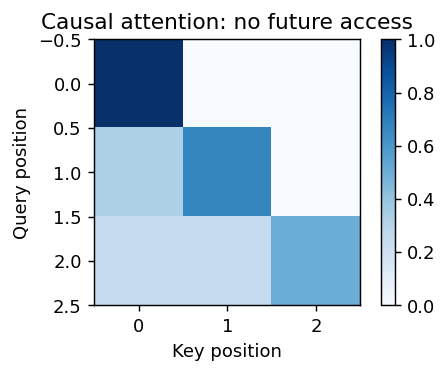

In [9]:
weights=softmax_np(np.array([1.,0.]))
print('Attention weights:',weights,'weighted value:',weights@np.array([10.,20.]))
H=np.array([[1.,0.],[0.,1.],[1.,1.]])
scores=H@H.T/np.sqrt(2)
mask=np.triu(np.ones((3,3),dtype=bool),k=1)
A=softmax_np(np.where(mask,-1e9,scores))
print('Causal attention:\n',A)
assert np.allclose(A[np.triu_indices(3,1)],0)
fig,ax=plt.subplots(figsize=(4,3))
im=ax.imshow(A,vmin=0,vmax=1,cmap='Blues'); fig.colorbar(im,ax=ax)
ax.set(xlabel='Key position',ylabel='Query position',title='Causal attention: no future access')
plt.tight_layout(); plt.show()


### Multi-head attention, residual connections, and feed-forward layers

Multiple heads apply attention in separate learned subspaces. Their outputs are concatenated and projected. A single head is sufficient to demonstrate the mechanism in our tiny model, but it is not a faithful scale replica of a frontier architecture.

A **residual connection** adds a transformed representation to the original. A common pre-normalisation block is
$$U=H+\operatorname{Attention}(\operatorname{LN}(H)),\qquad
H'=U+W_2\phi(\operatorname{LN}(U)W_1+b_1)+b_2.$$
LN means layer normalisation, $\phi$ is a nonlinear function, and weights and biases are learned. Our code uses $\tanh$ for a smooth activation. Modern large models often use gated feed-forward variants; the learning principles are the same but numerical behaviour differs.

For a token vector h, layer normalisation computes
$$\mu=\frac1d\sum_i h_i,\quad v=\frac1d\sum_i(h_i-\mu)^2,\quad
\operatorname{LN}(h)_i=\gamma_i\frac{h_i-\mu}{\sqrt{v+\epsilon}}+\beta_i.$$
$\gamma_i$ and $\beta_i$ are learned scale and shift, and a small $\epsilon>0$ prevents division by zero. The mean and variance are over feature coordinates, not over unrelated batch examples. All of this is numerical computation; calling it reasoning requires evidence about the behaviour it enables.


## 8. Scratchpads, latent state, and why more tokens can help

Compare two formats for our task. All arithmetic is **modulo 10**: keep the last digit of a sum.

**Direct:** `2+3+4=9#`  
**Scratchpad:** `2+3+4=5>9#`

The scratchpad explicitly exposes the intermediate result 5 before the final result 9. The model can condition the final token on that intermediate token. The symbol `#` means stop; `>` separates the intermediate and final digits. In general the first digit is $(a+b)\bmod10$ and the second is $(a+b+c)\bmod10$.

Why modulo 10? It makes the output length fixed and the task small enough to train on CPU. It also removes ordinary multi-digit carry handling, so success does **not** demonstrate general arithmetic. We choose a bounded task for transparency, not because it captures all reasoning.

An autoregressive model does not need a new layer for every generated step. It repeatedly applies the same learned network to an expanding context. This provides extra computation and a place to store intermediate symbols. At inference, weights stay fixed; activations and context change.

**Three distinctions:** (1) hidden activation computation occurs even for direct answers; (2) generated intermediate tokens can influence later computation; (3) a user-facing explanation may be produced after the answer or summarised from another sequence. These are not equivalent evidence about the actual mechanism.

Source anchors: Wei et al., *Chain-of-Thought Prompting* (2022), https://arxiv.org/abs/2201.11903; Wang et al., *Self-Consistency* (2022), https://arxiv.org/abs/2203.11171.


## 9. A small automatic-differentiation engine

We will implement the derivatives needed to train our Transformer, using NumPy rather than assuming access to a deep-learning framework. This makes the chain rule inspectable and keeps the default notebook dependency-light. Production frameworks are far more efficient and comprehensive.

Each `Tensor` stores data, a gradient, parent nodes, and a local backward function. `backward()` sorts the graph so children send gradient contributions to parents in reverse computational order.

**Broadcasting trap:** adding a bias of shape $(d,)$ to data of shape $(B,T,d)$ replicates it. During backpropagation, all replicated contributions must be **summed** back to shape $(d,)$. That is the purpose of `unbroadcast`.

**Matrix-product derivatives:** if $Y=AB$ and G is the upstream gradient, then
$$\frac{\partial L}{\partial A}=GB^\top,\qquad \frac{\partial L}{\partial B}=A^\top G.$$
For batched broadcasting, contributions for a shared matrix must again be summed. We implement matrix and batched matrix products; this engine deliberately does not support every NumPy feature or arbitrary vector-matrix broadcasting.


In [10]:
def unbroadcast(g, shape):
    while g.ndim > len(shape): g=g.sum(axis=0)
    for i,s in enumerate(shape):
        if s==1 and g.shape[i]!=1: g=g.sum(axis=i,keepdims=True)
    return g.reshape(shape)

class Tensor:
    def __init__(self,data,parents=(),backward=None):
        self.data=np.asarray(data,dtype=np.float64)
        self.grad=np.zeros_like(self.data)
        self.parents=parents
        self._backward=backward or (lambda:None)
    def __add__(self,other):
        other=as_tensor(other); out=Tensor(self.data+other.data,(self,other))
        def back():
            self.grad+=unbroadcast(out.grad,self.data.shape)
            other.grad+=unbroadcast(out.grad,other.data.shape)
        out._backward=back; return out
    __radd__=__add__
    def __neg__(self): return self*(-1.)
    def __sub__(self,other): return self+(-as_tensor(other))
    def __rsub__(self,other): return as_tensor(other)+(-self)
    def __mul__(self,other):
        other=as_tensor(other); out=Tensor(self.data*other.data,(self,other))
        def back():
            self.grad+=unbroadcast(out.grad*other.data,self.data.shape)
            other.grad+=unbroadcast(out.grad*self.data,other.data.shape)
        out._backward=back; return out
    __rmul__=__mul__
    def __pow__(self,power):
        out=Tensor(self.data**power,(self,))
        def back(): self.grad.__iadd__(out.grad*power*self.data**(power-1))
        out._backward=back; return out
    def __truediv__(self,other): return self*as_tensor(other)**(-1)
    def __matmul__(self,other):
        other=as_tensor(other); out=Tensor(self.data@other.data,(self,other))
        def back():
            self.grad+=unbroadcast(out.grad@np.swapaxes(other.data,-1,-2),self.data.shape)
            other.grad+=unbroadcast(np.swapaxes(self.data,-1,-2)@out.grad,other.data.shape)
        out._backward=back; return out
    def sum(self,axis=None,keepdims=False):
        out=Tensor(self.data.sum(axis=axis,keepdims=keepdims),(self,))
        def back():
            g=out.grad
            if axis is not None and not keepdims:
                axes=(axis,) if isinstance(axis,int) else axis
                for ax in sorted(a%self.data.ndim for a in axes): g=np.expand_dims(g,ax)
            self.grad+=np.broadcast_to(g,self.data.shape)
        out._backward=back; return out
    def mean(self,axis=None,keepdims=False):
        axes=tuple(range(self.data.ndim)) if axis is None else ((axis,) if isinstance(axis,int) else axis)
        n=np.prod([self.data.shape[a] for a in axes])
        return self.sum(axis,keepdims)/float(n)
    def exp(self):
        out=Tensor(np.exp(self.data),(self,))
        def back(): self.grad.__iadd__(out.grad*out.data)
        out._backward=back; return out
    def log(self):
        out=Tensor(np.log(self.data),(self,))
        def back(): self.grad.__iadd__(out.grad/self.data)
        out._backward=back; return out
    def tanh(self):
        out=Tensor(np.tanh(self.data),(self,))
        def back(): self.grad.__iadd__(out.grad*(1-out.data**2))
        out._backward=back; return out
    def transpose(self,axes):
        out=Tensor(self.data.transpose(axes),(self,))
        def back(): self.grad.__iadd__(out.grad.transpose(np.argsort(axes)))
        out._backward=back; return out
    def __getitem__(self,idx):
        out=Tensor(self.data[idx],(self,))
        def back(): np.add.at(self.grad,idx,out.grad)
        out._backward=back; return out
    def backward(self):
        if self.data.size!=1: raise ValueError('Start backward from a scalar loss.')
        order=[]; seen=set()
        def visit(t):
            if id(t) in seen:return
            seen.add(id(t))
            for p in t.parents:visit(p)
            order.append(t)
        visit(self)
        for t in order:t.grad.fill(0.)
        self.grad=np.ones_like(self.data)
        for t in reversed(order):t._backward()

def as_tensor(x): return x if isinstance(x,Tensor) else Tensor(x)
def softmax_t(x):
    shifted=x-Tensor(x.data.max(axis=-1,keepdims=True))
    e=shifted.exp()
    return e/e.sum(axis=-1,keepdims=True)

def cross_entropy_t(logits,targets,mask):
    # logits: B,T,V; targets and mask: B,T
    z=logits-Tensor(logits.data.max(axis=-1,keepdims=True))
    log_probs=z-z.exp().sum(axis=-1,keepdims=True).log()
    B,T=targets.shape
    selected=log_probs[np.arange(B)[:,None],np.arange(T)[None,:],targets]
    return -(selected*mask).sum()/float(mask.sum())
print('Autodiff engine ready.')


Autodiff engine ready.


### Why subtracting a detached maximum is legitimate here

In stable softmax we subtract the largest logit using a constant `Tensor`. Are we silently discarding a required gradient? A common shift cancels exactly in softmax and log-softmax. The derivative along that shift direction is zero. Consequently treating this numerical stabiliser as constant gives the same derivative of the final softmax or cross-entropy, away from numerical issues. This reasoning would **not** justify detaching an arbitrary value elsewhere in the computation.

Indexing uses `np.add.at` so repeated token identifiers accumulate all their gradients. Ordinary assignment would overwrite repeated entries and teach an incorrect embedding gradient. Small implementation details can completely change what is being trained.

## 10. Check the mathematics before trusting training

Finite differences approximate a derivative:
$$\frac{\partial L}{\partial w_i}\approx\frac{L(w_i+\varepsilon)-L(w_i-\varepsilon)}{2\varepsilon}.$$
Use a small but not microscopic epsilon; extremely small changes amplify floating-point cancellation. Our test compares derivatives for a graph containing an embedding lookup, normalisation, attention, and output loss. Passing a finite-difference check is evidence of local numerical consistency, not proof of every conceivable input case.


In [11]:
def gradient_check(param, loss_fn, indices, eps=1e-5):
    loss=loss_fn(); loss.backward(); analytic=param.grad.copy()
    errors=[]
    for idx in indices:
        original=param.data[idx]
        param.data[idx]=original+eps; plus=float(loss_fn().data)
        param.data[idx]=original-eps; minus=float(loss_fn().data)
        param.data[idx]=original
        numeric=(plus-minus)/(2*eps)
        errors.append(abs(numeric-analytic[idx]))
    return max(errors)
check_rng=np.random.default_rng(1)
check_W=Tensor(check_rng.normal(size=(3,2)))
check_X=Tensor(check_rng.normal(size=(2,4,3)))
err=gradient_check(check_W,lambda:((check_X@check_W).tanh()**2).mean(),[(0,0),(2,1)])
print('Batched matmul derivative max absolute error:',err)
assert err<1e-6


Batched matmul derivative max absolute error: 7.549946778873107e-12


## 11. Teacher forcing, masking, and supervised fine-tuning

During **teacher forcing**, the model receives the correct previous output token when predicting the next one. At deployment it receives its own previous token, which may be wrong. A low training loss therefore does not guarantee high free-generation accuracy. This difference is often called an exposure mismatch.

We train on prompt-plus-completion sequences, but compute loss only on the completion. For `2+3+4=5>9#`, the input starts `2+3+4=5>9` and the target is shifted one character left. The target 5 is predicted from the prefix ending `=`, not from a prefix already containing 5.

Define $m_t=1$ for completion targets and 0 for prompt targets. Then
$$L_{SFT}=-\frac{1}{\sum_t m_t}\sum_t m_t\log p_\theta(s_{t+1}\mid s_{\le t}).$$
SFT means **Supervised Fine-Tuning**. Here we use the same completion-only objective to train a tiny random model from scratch; technically it is supervised task training, not fine-tuning a pretrained language model. This distinction matters when comparing with R1 or other pretrained systems.

**Leakage trap:** if a future target is visible through an incorrect attention mask, apparent reasoning can be an implementation bug. We will explicitly test causality before training.


## 12. Construct a controlled reasoning dataset

To keep full training practical, the learned task uses **digits 0–4 and arithmetic modulo 5**. (Chapter 8 used modulo 10 only to illustrate the format.) For $a,b,c\in\{0,1,2,3,4\}$, define
$$u=(a+b)\bmod5,\qquad v=(u+c)\bmod5.$$
"Modulo 5" means the remainder after division by 5: $7\bmod5=2$. The prompt `2+3+4=` has u=0 and v=4. Its scratchpad target is `0>4#`; its direct target is `4#`.

There are $5^3=125$ distinct input triples. We split the **triples** into training, validation, and test sets before making either output format. No exact triple appears in multiple splits. We do not pretend that an unseen triple is an entirely novel mathematical concept: digits and pairwise combinations can still overlap.

Training data teaches the convention; the notebook cannot expect a random neural network to infer the rule from nothing. We will report both training-set and held-out performance to expose memorisation or failure to generalise.


In [12]:
MOD=5
all_triples=list(itertools.product(range(MOD),repeat=3))
split_rng=np.random.default_rng(31)
split_rng.shuffle(all_triples)
train_triples=all_triples[:90]
val_triples=all_triples[90:105]
test_triples=all_triples[105:]
assert not (set(train_triples)&set(test_triples))
assert not (set(val_triples)&set(test_triples))

def prompt_for(triple): return '+'.join(map(str,triple))+'='
def answer_for(triple): return sum(triple)%MOD
def completion_for(triple, scratch=True):
    a,b,c=triple; u=(a+b)%MOD; v=(u+c)%MOD
    return f'{u}>{v}#' if scratch else f'{v}#'
def make_arrays(triples,scratch=True):
    seqs=[encode(prompt_for(t)+completion_for(t,scratch)) for t in triples]
    arr=np.array(seqs,dtype=int)
    X,Y=arr[:,:-1],arr[:,1:]
    # Prompt has length 6. First completion target is predicted at input index 5.
    mask=np.zeros_like(Y,dtype=float); mask[:,5:]=1.
    return X,Y,mask
X_train,Y_train,M_train=make_arrays(train_triples)
example=(2,3,4)
print('Prompt:',prompt_for(example),'completion:',completion_for(example))
print('Splits:',len(train_triples),len(val_triples),len(test_triples))
print('X shape:',X_train.shape,'Y shape:',Y_train.shape)
print('Input:',decode(X_train[0]),'Target:',decode(Y_train[0]),'Mask:',M_train[0])


Prompt: 2+3+4= completion: 0>4#
Splits: 90 15 20
X shape: (90, 9) Y shape: (90, 9)
Input: 3+1+2=4>1 Target: +1+2=4>1# Mask: [0. 0. 0. 0. 0. 1. 1. 1. 1.]


## 13. Build the entire tiny causal Transformer

Our architecture has token and position embeddings, two pre-normalised single-head attention blocks, feed-forward layers, residual connections, and a final vocabulary projection. There is no hidden pretrained component.

For batch B and sequence T, embeddings have shape $(B,T,d)$. Attention scores have shape $(B,T,T)$. The final projection has shape $(B,T,V)$, one logit per vocabulary item at every position. The completion loss selects only the supervised target positions.

Parameter initialisation uses small random values. If every parameter were initialised identically, symmetry could prevent different units from learning distinct functions. Random initialisation breaks that symmetry. The random seed makes one run reproducible, not universal.

**Implementation differences from frontier systems:** no multi-head grouping, rotary embeddings, dropout, mixed precision, distributed training, key/value cache, or large-scale pretraining. Double precision helps check gradients; it is not a recommendation for large-model efficiency. Simplification is appropriate for learning only when the differences are explicit.


In [13]:
class TinyReasoner:
    def __init__(self,vocab_size=len(chars),d=24,hidden=48,layers=2,max_len=12,seed=0):
        self.rng=np.random.default_rng(seed); self.params=[]
        self.d=d; self.max_len=max_len
        def par(shape,scale=0.1,ones=False,zeros=False):
            data=np.ones(shape) if ones else (np.zeros(shape) if zeros else self.rng.normal(0,scale,shape))
            t=Tensor(data); self.params.append(t); return t
        self.E=par((vocab_size,d)); self.P=par((max_len,d))
        self.blocks=[]
        for _ in range(layers):
            self.blocks.append({
                'g1':par((d,),ones=True),'b1':par((d,),zeros=True),
                'q':par((d,d),d**-0.5),'k':par((d,d),d**-0.5),
                'v':par((d,d),d**-0.5),'o':par((d,d),d**-0.5),
                'g2':par((d,),ones=True),'b2':par((d,),zeros=True),
                'w1':par((d,hidden),d**-0.5),'b3':par((hidden,),zeros=True),
                'w2':par((hidden,d),hidden**-0.5),'b4':par((d,),zeros=True)})
        self.gf=par((d,),ones=True); self.bf=par((d,),zeros=True)
        self.head=par((d,vocab_size),d**-0.5)
    def ln(self,x,g,b):
        mu=x.mean(axis=-1,keepdims=True)
        centered=x-mu
        var=(centered**2).mean(axis=-1,keepdims=True)
        return centered*(var+1e-5)**(-0.5)*g+b
    def __call__(self,ids,return_attention=False):
        B,T=ids.shape
        if T>self.max_len: raise ValueError('Sequence exceeds context window.')
        h=self.E[ids]+self.P[np.arange(T)][None,:,:]
        attentions=[]
        causal=np.where(np.triu(np.ones((T,T),dtype=bool),1),-1e9,0.)[None,:,:]
        for b in self.blocks:
            z=self.ln(h,b['g1'],b['b1'])
            q,k,v=z@b['q'],z@b['k'],z@b['v']
            att=softmax_t((q@k.transpose((0,2,1)))/np.sqrt(self.d)+causal)
            attentions.append(att.data)
            h=h+(att@v)@b['o']
            z=self.ln(h,b['g2'],b['b2'])
            h=h+((z@b['w1']+b['b3']).tanh()@b['w2']+b['b4'])
        logits=self.ln(h,self.gf,self.bf)@self.head
        return (logits,attentions) if return_attention else logits
    def count_params(self): return sum(p.data.size for p in self.params)

model=TinyReasoner(seed=7)
print('Parameters:',model.count_params())
print('Logits shape:',model(X_train[:2]).data.shape)


Parameters: 10608
Logits shape: (2, 9, 15)


In [14]:
# Causality: modifying a future input must not change earlier logits.
probe=X_train[:2].copy(); modified=probe.copy(); modified[:,7]=(modified[:,7]+1)%MOD
before=model(probe).data; after=model(modified).data
causal_error=np.max(abs(before[:,:7]-after[:,:7]))
print('Earlier-logit change after a future-token edit:',causal_error)
assert causal_error<1e-10
# Check gradients through the full network, including embeddings and attention.
def probe_loss(): return cross_entropy_t(model(X_train[:2]),Y_train[:2],M_train[:2])
for label,param,idxs in [('output',model.head,[(0,0),(5,2)]),
                         ('embedding',model.E,[(0,0),(stoi['+'],3)]),
                         ('query',model.blocks[0]['q'],[(0,0),(2,4)])]:
    err=gradient_check(param,probe_loss,idxs)
    print(label,'gradient check error:',err)
    assert err<2e-5


Earlier-logit change after a future-token edit: 0.0
output gradient check error: 1.4816675664164336e-11
embedding gradient check error: 4.855675861392683e-10
query gradient check error: 1.6368087440987722e-11


### Reading the checks

The causality check changes input index 7 and checks outputs strictly before it. Outputs at index 7 or later may legitimately change. This is a test of a concrete property, not a visual impression of a triangular mask.

The gradient checks perturb selected parameters. Embeddings with repeated identifiers require summation; attention requires gradients through queries, keys, and values; normalisation requires gradients through its mean and variance. All are handled by composing operations in our engine.

An attention heatmap can show where this model combines information. It is not, by itself, a faithful explanation of every computation or a proof that a particular token caused the answer. Later we will use interventions.


## 14. Optimisation: gradient clipping and Adam

Stochastic optimisation estimates a dataset gradient using a mini-batch. Reusing the same few examples can reduce training loss while leaving held-out accuracy low.

We clip the **global gradient norm** to a threshold C:
$$g\leftarrow g\min\left(1,\frac{C}{\|g\|_2+\epsilon}\right).$$
$\|g\|_2=\sqrt{\sum_i g_i^2}$ is the Euclidean length of all parameter gradients combined. This rescales large updates; it does not repair an incorrect gradient.

Adam maintains exponential averages of gradients and squared gradients:
$$m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\quad
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2.$$
Because both start at zero, bias-correct them:
$$\hat m_t=\frac{m_t}{1-\beta_1^t},\quad \hat v_t=\frac{v_t}{1-\beta_2^t},\quad
\theta_t=\theta_{t-1}-\eta\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.$$
All squared and divided terms are coordinate-wise. $t$ counts updates, $\beta_1,\beta_2$ control smoothing, and $\eta$ is the learning rate. The notation $v_t$ here is an optimiser statistic, unrelated to attention values V.

We train direct and scratchpad models with the same parameter count and update count. **This is not an equal-compute comparison:** scratchpad sequences are longer. We report processed tokens and elapsed time so the difference is visible. A fairer compute study would equalise measured operations or a clearly specified budget.


Scratchpad cost: {'seconds': 4.209674419999828, 'input_tokens': 216000, 'supervised_tokens': 96000}
Direct cost: {'seconds': 3.673900897999829, 'input_tokens': 168000, 'supervised_tokens': 48000}


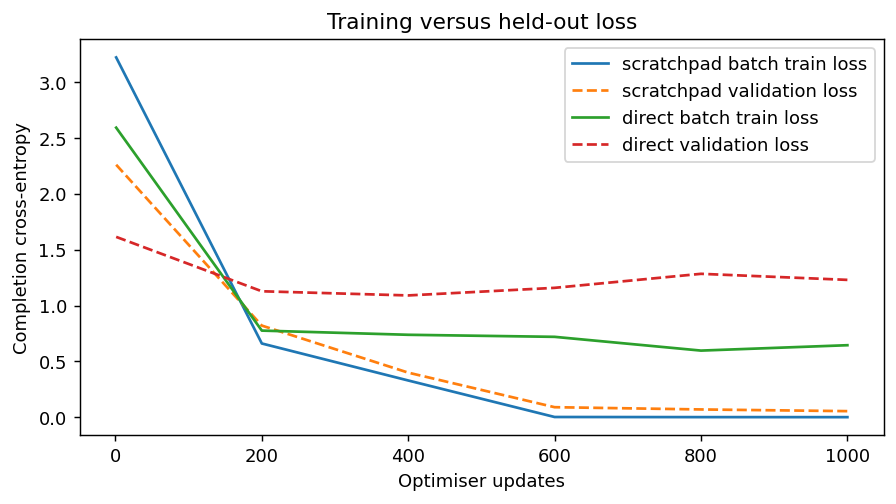

In [15]:
class AdamNP:
    def __init__(self,params,lr=0.003,beta1=0.9,beta2=0.999,clip=1.0):
        self.params=params; self.lr=lr; self.b1=beta1; self.b2=beta2; self.clip=clip
        self.m=[np.zeros_like(p.data) for p in params]
        self.v=[np.zeros_like(p.data) for p in params]; self.t=0
    def step(self):
        self.t+=1
        norm=np.sqrt(sum(float((p.grad**2).sum()) for p in self.params))
        scale=min(1.,self.clip/(norm+1e-12))
        for i,p in enumerate(self.params):
            g=p.grad*scale
            self.m[i]=self.b1*self.m[i]+(1-self.b1)*g
            self.v[i]=self.b2*self.v[i]+(1-self.b2)*g*g
            mh=self.m[i]/(1-self.b1**self.t); vh=self.v[i]/(1-self.b2**self.t)
            p.data-=self.lr*mh/(np.sqrt(vh)+1e-8)
        return norm

def fit_model(scratch,steps=1000,seed=7,batch_size=24):
    net=TinyReasoner(seed=seed); opt=AdamNP(net.params)
    X,Y,M=make_arrays(train_triples,scratch)
    VX,VY,VM=make_arrays(val_triples,scratch)
    local_rng=np.random.default_rng(12)
    hist=[]; start=time.perf_counter()
    for step in range(1,steps+1):
        ix=local_rng.integers(0,len(X),size=batch_size)
        loss=cross_entropy_t(net(X[ix]),Y[ix],M[ix]); loss.backward(); norm=opt.step()
        if step==1 or step%200==0 or step==steps:
            vl=float(cross_entropy_t(net(VX),VY,VM).data)
            hist.append((step,float(loss.data),vl))
    seconds=time.perf_counter()-start
    return net,np.array(hist),{'seconds':seconds,'input_tokens':steps*batch_size*X.shape[1],
                               'supervised_tokens':int(steps*batch_size*M[0].sum())}
# Increase to 3000 for an extended experiment; do not tune on the test split.
TRAIN_STEPS=1000
scratch_model,scratch_history,scratch_cost=fit_model(True,TRAIN_STEPS)
direct_model,direct_history,direct_cost=fit_model(False,TRAIN_STEPS)
print('Scratchpad cost:',scratch_cost)
print('Direct cost:',direct_cost)
fig,ax=plt.subplots(figsize=(7,4))
for name,hist in [('scratchpad',scratch_history),('direct',direct_history)]:
    ax.plot(hist[:,0],hist[:,1],label=name+' batch train loss')
    ax.plot(hist[:,0],hist[:,2],linestyle='--',label=name+' validation loss')
ax.set(xlabel='Optimiser updates',ylabel='Completion cross-entropy',title='Training versus held-out loss')
ax.legend(); plt.tight_layout(); plt.show()


### Interpreting the curves without inventing a conclusion

Training loss uses the current sampled mini-batch; validation loss uses all validation triples. They need not be ordered at every point. A train/validation gap can indicate overfitting, sampling variability, or different example difficulty.

If the scratchpad model performs worse, do not change the story to "scratchpads always help." The added intermediate prediction can make this tiny task harder to learn. If it performs better, do not conclude that it proves general reasoning. Both results must be interpreted with seeds, budgets, and data scope.

This is an experiment to inspect, not a prearranged demonstration with guaranteed favourable numbers. Learn to explain what happened in your actual run.


## 15. Free generation, parsing, and held-out evaluation

Greedy decoding chooses the highest-probability token at each step:
$$\hat y_t=\arg\max_v p_\theta(v\mid x,\hat y_{<t}).$$
The hat indicates a generated value. Greedy decoding is locally optimal for each token, not guaranteed to find the most probable whole sequence or a correct answer.

For sampling, draw $y_t$ from the softmax distribution at a stated temperature. Fixing a seed makes a particular sampling experiment repeatable. It does not make sampled attempts independent in their errors: the same learned misconceptions may appear repeatedly.

Our strict parser requires the full expected output format, including the stop token. A final-digit metric checks the answer only; a trace metric also checks the intermediate digit. They answer different questions. A malformed response is counted as unsuccessful rather than silently repaired using the answer key.


In [16]:
def generate_batch(net,triples,scratch=True,sample=False,temperature=1.,seed=0):
    g=np.random.default_rng(seed)
    ids=np.array([encode(prompt_for(t)) for t in triples],dtype=int)
    n_new=4 if scratch else 2
    for _ in range(n_new):
        probs=softmax_np(net(ids).data[:,-1,:],temperature)
        nxt=np.array([g.choice(len(chars),p=p) for p in probs]) if sample else probs.argmax(axis=-1)
        ids=np.concatenate([ids,nxt[:,None]],axis=1)
    return [decode(row[6:]) for row in ids]

def parse_completion(text,scratch=True):
    pattern=r'([0-4])>([0-4])#' if scratch else r'([0-4])#'
    match=re.fullmatch(pattern,text)
    if not match:return None
    return tuple(map(int,match.groups()))

def evaluate_generated(net,triples,scratch=True):
    outputs=generate_batch(net,triples,scratch)
    parsed=[parse_completion(s,scratch) for s in outputs]
    final=np.array([p is not None and p[-1]==answer_for(t) for p,t in zip(parsed,triples)])
    exact=np.array([o==completion_for(t,scratch) for o,t in zip(outputs,triples)])
    return {'final_accuracy':float(final.mean()),'exact_completion':float(exact.mean()),
            'format_valid':float(np.mean([p is not None for p in parsed])),
            'outputs':outputs,'correct':final}
results={}
for name,net,scratch in [('scratchpad',scratch_model,True),('direct',direct_model,False)]:
    results[name]={}
    for split,triples in [('train',train_triples),('validation',val_triples),('test',test_triples)]:
        r=evaluate_generated(net,triples,scratch); results[name][split]=r
        print(name,split,{k:round(v,3) for k,v in r.items() if isinstance(v,float)})
print('\nHeld-out examples:')
for t,o in zip(test_triples[:8],results['scratchpad']['test']['outputs'][:8]):
    print(prompt_for(t),'generated',o,'expected',completion_for(t))


scratchpad train {'final_accuracy': 1.0, 'exact_completion': 1.0, 'format_valid': 1.0}
scratchpad validation {'final_accuracy': 0.933, 'exact_completion': 0.933, 'format_valid': 1.0}
scratchpad test {'final_accuracy': 1.0, 'exact_completion': 1.0, 'format_valid': 1.0}
direct train {'final_accuracy': 0.389, 'exact_completion': 0.389, 'format_valid': 1.0}
direct validation {'final_accuracy': 0.0, 'exact_completion': 0.0, 'format_valid': 1.0}
direct test {'final_accuracy': 0.0, 'exact_completion': 0.0, 'format_valid': 1.0}

Held-out examples:
4+2+2= generated 1>3# expected 1>3#
4+3+3= generated 2>0# expected 2>0#
2+2+4= generated 4>3# expected 4>3#
4+1+3= generated 0>3# expected 0>3#
2+4+0= generated 1>1# expected 1>1#
0+3+3= generated 3>1# expected 3>1#
0+3+1= generated 3>4# expected 3>4#
2+0+1= generated 2>3# expected 2>3#


### A tricky distinction: being right for the wrong reason

A scratchpad output can contain an incorrect intermediate result and a correct final result. Its final-answer accuracy is 1 for that example, but its trace correctness is 0. Conversely, a correct intermediate result can be followed by a wrong final step.

Neither an explicit trace nor a high final-answer score alone identifies the internal algorithm. The model could use the intermediate token, ignore it, or combine it with a separately computed answer. Interventions provide stronger evidence than simply reading the text.

## 16. Intervene on the intermediate result

We now force a candidate intermediate digit u after the prompt and inspect the model's next final digit. This is **not** a normal generation benchmark. It is a controlled intervention on context.

For a system that exclusively trusts the supplied intermediate, the final answer should be $(u+c)\bmod5$. If it reconstructs the sum from the prompt, it may retain the true final answer despite the changed u. Mixed behaviour is possible. These are hypotheses, not labels to assign from one example.

Replacing a generated digit is a token-level intervention; it does not isolate a particular hidden neuron or feature. It also creates contexts that may be rare in training. Interpret effects with these limits.


forced intermediate | predicted final token | final if supplied intermediate trusted
(0, '4', 4)
(1, '0', 0)
(2, '1', 1)
(3, '2', 2)
(4, '3', 3)


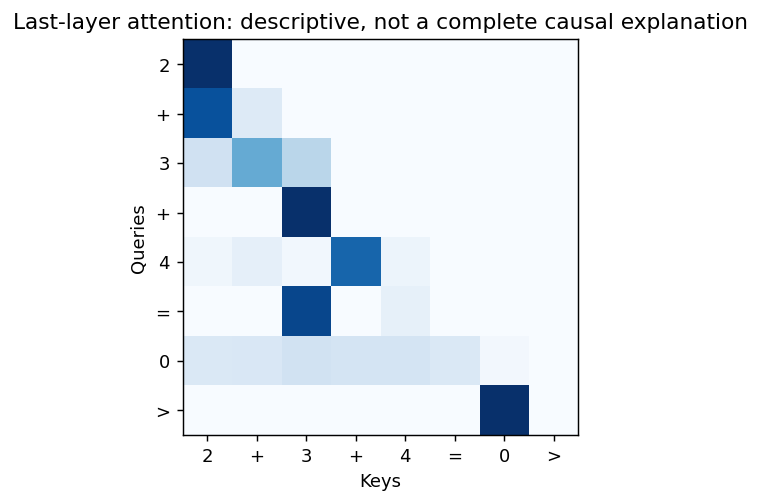

In [17]:
intervention_triple=(2,3,4)
rows=[]
for forced_u in range(MOD):
    prefix=prompt_for(intervention_triple)+str(forced_u)+'>'
    probs=softmax_np(scratch_model(np.array([encode(prefix)])).data[0,-1])
    predicted=decode([probs.argmax()])
    rows.append((forced_u,predicted,(forced_u+intervention_triple[2])%MOD))
print('forced intermediate | predicted final token | final if supplied intermediate trusted')
for row in rows:print(row)
_,attentions=scratch_model(np.array([encode(prompt_for(intervention_triple)+'0>')]),True)
fig,ax=plt.subplots(figsize=(6,4))
ax.imshow(attentions[-1][0],cmap='Blues'); tokens=list(prompt_for(intervention_triple)+'0>')
ax.set_xticks(range(len(tokens)),tokens); ax.set_yticks(range(len(tokens)),tokens)
ax.set(title='Last-layer attention: descriptive, not a complete causal explanation',xlabel='Keys',ylabel='Queries')
plt.tight_layout();plt.show()


## 17. Multiple attempts: self-consistency is not an oracle

Suppose one independently sampled attempt succeeds with probability p. The probability that none of k attempts succeeds is $(1-p)^k$, so
$$P(\text{at least one success})=1-(1-p)^k.$$
This equation assumes independent attempts with the same p. It describes the existence of a successful candidate, **not** the ability to recognise it. With p=0.3 and k=5, the probability is about 0.832. A deployed system cannot claim that success rate without a sufficiently good selector.

**Majority voting** selects the most frequent final answer. Self-consistency samples diverse intermediate paths and aggregates their answers. It can help when correct answers recur while mistakes are dispersed. It can fail when the model repeatedly makes the same systematic error. If each attempt is more likely wrong than right in a binary task, more majority votes can make the result worse.

Do not confuse three procedures: **pass@k** asks whether at least one candidate passes; **majority vote** chooses the most frequent answer; **best-of-k** chooses the candidate assigned the highest score by a verifier. These have different assumptions and costs.


In [18]:
K=9
sampled=[]
for k in range(K):
    sampled.append(generate_batch(scratch_model,test_triples,True,sample=True,temperature=0.8,seed=100+k))
sample_matrix=np.array(sampled,dtype=object).T
sample_answers=[]
for row in sample_matrix:
    parsed=[parse_completion(x,True) for x in row]
    sample_answers.append([p[-1] if p is not None else None for p in parsed])
for k in [1,3,5,9]:
    exists=[]; voted=[]
    for triple,answers in zip(test_triples,sample_answers):
        subset=answers[:k]
        # Invalid outputs remain failed attempts. Voting ignores invalid answers;
        # an all-invalid set yields failure. Ties use the earliest sampled answer.
        valid=[a for a in subset if a is not None]
        choice=Counter(valid).most_common(1)[0][0] if valid else None
        exists.append(answer_for(triple) in subset)
        voted.append(choice==answer_for(triple))
    print(f'k={k}: empirical any-success={np.mean(exists):.3f}, majority={np.mean(voted):.3f}')
print('These are small-sample estimates, not a guarantee that voting helps.')


k=1: empirical any-success=1.000, majority=1.000
k=3: empirical any-success=1.000, majority=1.000
k=5: empirical any-success=1.000, majority=0.950
k=9: empirical any-success=1.000, majority=0.950
These are small-sample estimates, not a guarantee that voting helps.


### An unbiased finite-pool pass@k estimator

If n exchangeable sampled candidates contain c successes and k≤n, a standard estimator is
$$\widehat{\mathrm{pass@k}}=1-\frac{\binom{n-c}{k}}{\binom nk}.$$
$\binom nk$ counts subsets of k items from n. The fraction is the proportion of k-subsets containing no success. If n−c<k, that fraction is zero. Average this quantity across problems; do not insert an average success rate into the formula and assume equivalence.

This estimator is different from simply checking the first k attempts, although both have meaningful interpretations under stated sampling procedures. Neither addresses how an application selects the successful solution.


In [19]:
def pass_at_k(n,c,k):
    if not 1<=k<=n: raise ValueError('Require 1 <= k <= n')
    return 1. if n-c<k else 1-math.comb(n-c,k)/math.comb(n,k)
for k in [1,3,5,9]:
    estimates=[]
    for t,answers in zip(test_triples,sample_answers):
        c=sum(a==answer_for(t) for a in answers)
        estimates.append(pass_at_k(K,c,k))
    print('Estimated pass@',k,'=',round(float(np.mean(estimates)),3))


Estimated pass@ 1 = 0.944
Estimated pass@ 3 = 0.967
Estimated pass@ 5 = 0.978
Estimated pass@ 9 = 1.0


## 18. Search: represent a problem as states and actions

Reasoning can involve exploring alternatives rather than committing to one linear trace. A **state** represents relevant information. An **action** changes the state. A **transition function** computes the next state. A **goal test** says whether the state satisfies the objective.

Consider two jugs with capacities 3 and 5 litres. We may fill a jug, empty it, or pour from one into the other. Starting empty, obtain exactly 4 litres in the 5-litre jug. State $(a,b)$ records both current amounts.

Breadth-first search (BFS) explores all depth-0 states, then depth-1, and so on. For equal-cost actions it finds a shortest action sequence if one exists. The queue is explicit memory. A visited set prevents loops. With branching factor b and solution depth d, a tree search can require order $b^d$ work. Finite state deduplication can reduce that substantially.

This is an exact algorithm for a specified environment. An LLM can propose states or actions, but then its transition predictions may be wrong. A reliable external simulator removes one source of error. The whole system's success should not be credited solely to the language model.


In [20]:
def jug_actions(state):
    a,b=state; p=min(a,5-b); q=min(b,3-a)
    options=[('fill 3L',(3,b)),('fill 5L',(a,5)),('empty 3L',(0,b)),
             ('empty 5L',(a,0)),('pour 3L to 5L',(a-p,b+p)),('pour 5L to 3L',(a+q,b-q))]
    return [(name,s) for name,s in options if s!=state]
def bfs_jugs(budget=100):
    queue=deque([((0,0),[]) ]); seen={(0,0)}; expanded=0
    while queue and expanded<budget:
        state,path=queue.popleft()
        if state[1]==4:return path,expanded
        expanded+=1
        for name,nxt in jug_actions(state):
            if nxt not in seen:
                seen.add(nxt);queue.append((nxt,path+[(name,nxt)]))
    return None,expanded
jug_path,expanded=bfs_jugs()
print('Expanded states:',expanded,'Plan length:',len(jug_path))
for action,state in jug_path:print(action,'->',state)
assert jug_path[-1][1][1]==4


Expanded states: 13 Plan length: 6
fill 5L -> (0, 5)
pour 5L to 3L -> (3, 2)
empty 3L -> (0, 2)
pour 5L to 3L -> (2, 0)
fill 5L -> (2, 5)
pour 5L to 3L -> (3, 4)


### Beam search, best-first search, and Tree of Thoughts

**Beam search** keeps only a limited number of promising partial candidates at each step. It saves memory but may discard the only correct path. Ordinary language-model beam search ranks text probability; the most probable explanation is not necessarily correct.

**Best-first search** prioritises states according to a score or heuristic. Its guarantees depend on the algorithm and score assumptions. A learned value estimate can guide search, but can also confidently reject promising branches.

**Tree of Thoughts** is a system-level framework that explores intermediate text proposals using evaluation and search. It is not simply another name for Transformer attention, and not every reasoning model literally builds a tree. Model-generated search, explicit external search, and latent internal computation must be distinguished.

Source: Yao et al., *Tree of Thoughts: Deliberate Problem Solving with Large Language Models* (2023), https://arxiv.org/abs/2305.10601.


In [21]:
def verify_jug_plan(path):
    state=(0,0)
    for name,nxt in path:
        if (name,nxt) not in jug_actions(state):return False
        state=nxt
    return state[1]==4
assert verify_jug_plan(jug_path)
assert not verify_jug_plan([('invent water',(0,4))])
print('Real plan verified:',verify_jug_plan(jug_path))
print('Fabricated one-step plan verified:',verify_jug_plan([('invent water',(0,4))]))


Real plan verified: True
Fabricated one-step plan verified: False


## 19. Verification: final answers, processes, and tools

A **generator** proposes a candidate. A **verifier** checks or scores it. A **selector** chooses a candidate based on those scores. These roles can be played by separate models or by a combination of models and exact programs.

An **outcome reward** checks the final answer. A **process reward** checks intermediate steps. If $r_t$ scores step t, a simple aggregate is $\sum_t r_t$, but this rewards longer traces unless carefully designed. A minimum step score is conservative but sensitive to noisy judges. There is no universally correct aggregation rule.

For our arithmetic task we can independently calculate both u and v. This gives an exact toy verifier. It is effectively an oracle for this bounded task; an open-ended scientific argument does not come with such a cheap oracle. Calling an LLM judge a verifier does not make its judgments ground truth.

For code, passing tests means passing those tests; untested cases may fail. For formal mathematics, a proof assistant checks a theorem under formal definitions and axioms; it does not guarantee those definitions match an informal real-world claim.

Source: Lightman et al., *Let's Verify Step by Step* (2023), https://arxiv.org/abs/2305.20050.


In [22]:
def verify_arithmetic(triple,text):
    parsed=parse_completion(text,True)
    if parsed is None:return {'format':False,'intermediate':False,'final':False,'all':False}
    u,v=parsed; true_u=(triple[0]+triple[1])%MOD
    inter=u==true_u; final=v==answer_for(triple)
    return {'format':True,'intermediate':inter,'final':final,'all':inter and final}
for txt in ['0>4#','1>4#','0>3#','I think four']:
    print(txt,verify_arithmetic((2,3,4),txt))
# Oracle selection among sampled candidates: useful upper bound, not deployable general reasoning.
oracle_success=[]
for t,candidates in zip(test_triples,sample_matrix):
    oracle_success.append(any(verify_arithmetic(t,c)['all'] for c in candidates))
print('Exact-trace oracle success among 9 candidates:',np.mean(oracle_success))


0>4# {'format': True, 'intermediate': True, 'final': True, 'all': True}
1>4# {'format': True, 'intermediate': False, 'final': True, 'all': False}
0>3# {'format': True, 'intermediate': True, 'final': False, 'all': False}
I think four {'format': False, 'intermediate': False, 'final': False, 'all': False}
Exact-trace oracle success among 9 candidates: 1.0


### Reward hacking is an objective-design problem

Suppose a weak evaluator rewards any output containing the expected digit. A rambling string listing every digit receives reward even though it does not solve the task. Optimisation can amplify that loophole. This is a toy **reward-hacking** example: the measured target differs from the intended target.

A stricter parser helps this example but does not solve every evaluation weakness. Evaluation itself becomes an engineering and scientific problem. If the reward is a learned model, the generator may exploit systematic blind spots.


In [23]:
triple=(2,3,4); hacked='My answers are 0 1 2 3 4'
weak_reward=float(str(answer_for(triple)) in hacked)
strict_reward=float(verify_arithmetic(triple,hacked)['all'])
print('Weak reward:',weak_reward,'Strict reward:',strict_reward)
assert weak_reward==1 and strict_reward==0


Weak reward: 1.0 Strict reward: 0.0


## 20. Compute budgets and scaling claims

The central optimisation problem is not simply "generate as much as possible":
$$\max_{\text{strategy }\pi}\mathbb E[\text{success}(x,\pi)]\quad\text{subject to}\quad
\mathbb E[C(x,\pi)]\le B.$$
$\pi$ is an inference strategy, x a task, C its cost, and B the allowed budget. This is an **average-budget** constraint. A strict per-task budget $C(x,\pi)\le B$ is a different requirement. A strategy might allocate more computation to harder tasks under the average constraint.

Count generated candidates, generated tokens, verifier calls, wall time, and if possible actual operations. More tokens at different model sizes are not equal compute. Wall time depends on hardware, batching, caching, and network overhead. Dollar prices can change independently of compute.

For a simple illustration, suppose the first step succeeds with probability q independently at every stage of a d-step chain. Then full success is $q^d$. With q=0.98 and d=50, that is only about 0.364. This is an illustrative independence model; real errors are dependent, and systems may recover. It explains why long-horizon reliability needs more than impressive isolated steps.

Source: Snell et al., *Scaling LLM Test-Time Compute Optimally Can Be More Effective than Scaling Model Parameters* (2024), https://arxiv.org/abs/2408.03314. Its findings are conditional on the tested models, tasks, and budgets, not a universal scaling law.


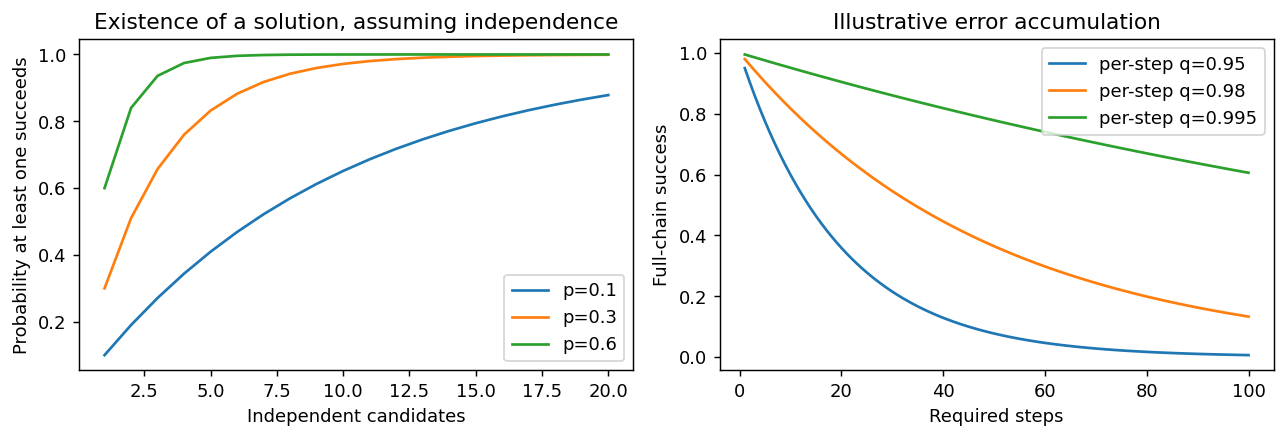

In [24]:
ks=np.arange(1,21)
fig,axes=plt.subplots(1,2,figsize=(10,3.5))
for p in [0.1,0.3,0.6]:
    axes[0].plot(ks,1-(1-p)**ks,label=f'p={p}')
axes[0].set(xlabel='Independent candidates',ylabel='Probability at least one succeeds',title='Existence of a solution, assuming independence')
axes[0].legend()
depths=np.arange(1,101)
for q in [0.95,0.98,0.995]: axes[1].plot(depths,q**depths,label=f'per-step q={q}')
axes[1].set(xlabel='Required steps',ylabel='Full-chain success',title='Illustrative error accumulation')
axes[1].legend();plt.tight_layout();plt.show()


## 21. Reinforcement learning: states, actions, policies, and rewards

In reinforcement learning a **policy** chooses actions given a state. For language generation, the state can be the prompt plus generated prefix, and the next token is an action. A completed response is a **trajectory**. A reward evaluates the trajectory or some of its steps.

Let x be a prompt and y a complete response. The policy is $\pi_\theta(y\mid x)$ and the reward is $R(x,y)$. The objective is
$$J(\theta)=\mathbb E_{x\sim D}\mathbb E_{y\sim\pi_\theta(\cdot\mid x)}[R(x,y)].$$
$D$ is the prompt distribution and $\mathbb E$ means expectation, a probability-weighted average. Training maximises expected reward, not the probability of matching a single demonstrated response.

For a sequence, the policy probability factorises by token just like a language model:
$$\log\pi_\theta(y\mid x)=\sum_t\log\pi_\theta(y_t\mid x,y_{<t}).$$
Taking logarithms turns a product into a sum. This makes gradients manageable. The reward can be discontinuous or come from an external program; we do not need to differentiate through the environment when using a policy gradient.

**Training/inference distinction:** reinforcement learning updates weights across many attempts during training. A model considering several answers at inference is not automatically doing reinforcement learning, because no parameter update need occur.


## 22. Derive the policy gradient instead of treating it as magic

For one fixed prompt with finitely many responses:
$$J(\theta)=\sum_y\pi_\theta(y\mid x)R(x,y).$$
Assume the reward function has no direct dependence on $\theta$ and the distribution is differentiable. Differentiate:
$$\nabla_\theta J=\sum_y R(x,y)\nabla_\theta\pi_\theta(y\mid x).$$
Use $\nabla\pi=\pi\nabla\log\pi$, valid when $\pi>0$:
$$\nabla_\theta J=\mathbb E_y\left[R(x,y)\nabla_\theta\log\pi_\theta(y\mid x)\right].$$
This is the **score-function estimator**, often called REINFORCE. A sampled high-reward response increases the probability of actions along that response. A low-reward response need not be explicitly punished unless we compare it against a baseline.

Subtract a baseline $b(x)$ that does not depend on the sampled response:
$$\nabla J=\mathbb E_y[(R-b(x))\nabla\log\pi_\theta(y\mid x)].$$
Why is this unbiased? Because
$$\mathbb E_y[b(x)\nabla\log\pi_\theta(y\mid x)]
=b(x)\sum_y\nabla\pi_\theta(y\mid x)=b(x)\nabla1=0.$$
The **advantage estimate** $A=R-b(x)$ says whether an attempt did better than its reference expectation. The baseline reduces variance without changing the expected gradient, provided the required independence and stop-gradient treatment hold.

A gradient can still have high variance. Sparse success means most samples provide weak information. Good initial competence and well-designed tasks can be critical.


In [25]:
# One-state, three-action example: exact expected-reward gradient vs Monte Carlo.
logits=np.array([0.2,-0.1,0.4]); rewards=np.array([0.,1.,0.3])
p=softmax_np(logits); J=p@rewards
exact_grad=p*(rewards-J)
mc_rng=np.random.default_rng(5)
actions=mc_rng.choice(3,size=100000,p=p)
onehot=np.eye(3)[actions]
mc_grad=((rewards[actions]-J)[:,None]*(onehot-p)).mean(axis=0)
print('Expected reward:',J,'Exact gradient:',exact_grad,'Sampled gradient:',mc_grad)
assert np.max(abs(exact_grad-mc_grad))<0.01


Expected reward: 0.3737867822955787 Exact gradient: [-0.1262  0.1566 -0.0304] Sampled gradient: [-0.126   0.1568 -0.0308]


### Credit assignment is not an explanation of every step

If only a final answer is rewarded, REINFORCE gives the same terminal advantage to all sampled actions in the response. It does not know which individual step caused success. A misleading intermediate step can be reinforced if it co-occurs with a correct answer.

Process feedback, a learned value function, counterfactual experiments, or additional structure can improve credit assignment. Each has costs and failure modes. An apparent "self-correction" sentence can be a useful action, a learned stylistic habit, or both. Its causal role must be tested.

## 23. KL regularisation and PPO

A reward-optimised policy may drift away from useful pretrained behaviour. A common regulariser penalises divergence from a reference policy:
$$J_{reg}=\mathbb E_{y\sim\pi_\theta}[R(x,y)]-\beta D_{KL}(\pi_\theta\|\pi_{ref}).$$
For categorical distributions p and q,
$$D_{KL}(p\|q)=\sum_i p_i\log\frac{p_i}{q_i}.$$
$\beta\ge0$ controls penalty strength; $\pi_{ref}$ is usually held fixed. KL is nonnegative and asymmetric. A per-token KL averaged over visited prefixes is related to sequence KL under the appropriate on-policy distribution; mixing arbitrary averaging rules can change the objective.

**Proximal Policy Optimisation (PPO)** uses data sampled from a frozen old policy and limits policy changes through a clipped surrogate. Define the action probability ratio
$$r_t(\theta)=\frac{\pi_\theta(a_t\mid s_t)}{\pi_{old}(a_t\mid s_t)}.$$
A standard maximised term is
$$L_{clip}=\mathbb E_t\left[\min\left(r_t A_t,\operatorname{clip}(r_t,1-\epsilon,1+\epsilon)A_t\right)\right].$$
$\epsilon$ is a clipping range and $A_t$ an advantage estimated using rollout data. The old probabilities and advantages are treated as fixed during the update. For positive A, the objective stops rewarding excessively large probability increases. For negative A, the minimum has the complementary effect. Clipping is an optimisation heuristic, not a strict bound on every resulting probability or on KL.

A training loss is often the negative of a maximised objective. Losing track of that sign is a common implementation error.

Source: Schulman et al., *Proximal Policy Optimization Algorithms* (2017), https://arxiv.org/abs/1707.06347.


KL example: 0.020111675129058065


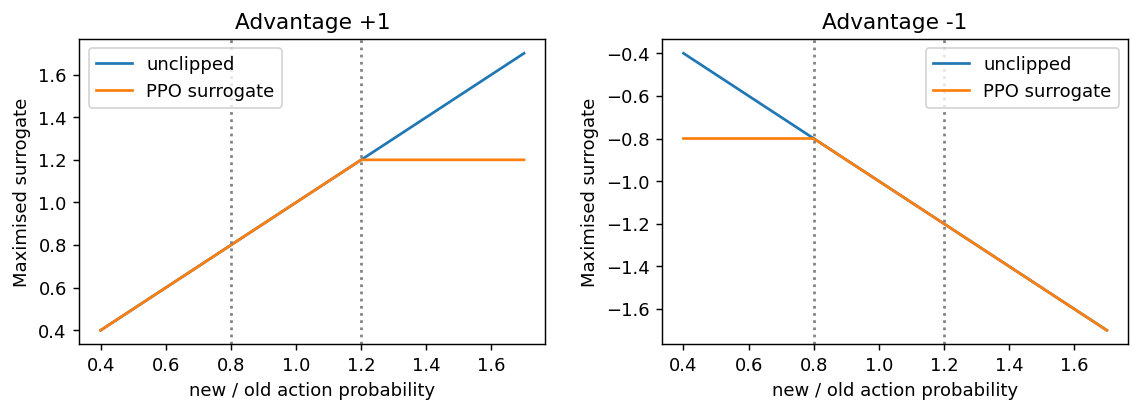

In [26]:
ratios=np.linspace(0.4,1.7,200); epsilon=0.2
fig,axes=plt.subplots(1,2,figsize=(9,3.3))
for ax,adv in zip(axes,[1.,-1.]):
    raw=ratios*adv
    clipped=np.minimum(raw,np.clip(ratios,1-epsilon,1+epsilon)*adv)
    ax.plot(ratios,raw,label='unclipped');ax.plot(ratios,clipped,label='PPO surrogate')
    ax.axvline(1-epsilon,color='grey',linestyle=':');ax.axvline(1+epsilon,color='grey',linestyle=':')
    ax.set(xlabel='new / old action probability',ylabel='Maximised surrogate',title=f'Advantage {adv:+.0f}')
    ax.legend()
plt.tight_layout();plt.show()
print('KL example:',np.sum(p*np.log(p/np.array([1/3]*3))))


## 24. GRPO: group-relative feedback, with its tricky assumptions

**Group Relative Policy Optimisation (GRPO)** samples a group of G responses for the same prompt. A common advantage estimate is
$$\hat A_i=\frac{R_i-\bar R}{s_R+\delta},\qquad
\bar R=\frac1G\sum_{j=1}^G R_j.$$
$R_i$ is response i's reward, $s_R$ is the group reward standard deviation, and $\delta>0$ avoids division by zero. Exact standard-deviation conventions and normalisation choices vary across implementations. A clipped policy-ratio objective can then use these group-relative advantages, often with a KL term.

This removes the need for the particular learned critic used in standard PPO-style implementations, but it does not remove the need for reward evaluation. If every response has the same reward, all advantages are zero: the group provides no within-group ranking signal.

**Subtlety:** the group mean includes the sample being scored. Unlike an independent baseline, it changes the finite-sample estimator; without standard-deviation normalisation its expected gradient is scaled by $(G-1)/G$ under independent samples. Dividing by a random group standard deviation changes it further. It is inaccurate to call every group-normalised estimator an exactly unbiased version of REINFORCE.

A **leave-one-out baseline** for response i uses the average reward of the other G−1 responses. Under independent sampling conditional on the prompt, that baseline is independent of response i and retains the score-function argument. Group-normalised GRPO and leave-one-out REINFORCE should not be silently treated as identical.

GRPO was introduced in the DeepSeekMath work and used in DeepSeek reasoning training. Many later variants change normalisation, clipping, length treatment, and sampling. Always identify which objective an implementation actually uses.

Sources: Shao et al., *DeepSeekMath* (2024), https://arxiv.org/abs/2402.03300; DeepSeek-AI, *DeepSeek-R1* (2025), https://arxiv.org/abs/2501.12948.


In [27]:
group_rewards=np.array([0.,0.,1.,1.])
grpo_adv=(group_rewards-group_rewards.mean())/(group_rewards.std()+1e-8)
loo_baselines=(group_rewards.sum()-group_rewards)/(len(group_rewards)-1)
loo_adv=group_rewards-loo_baselines
print('Rewards:',group_rewards)
print('Group-standardised advantages:',grpo_adv)
print('Leave-one-out advantages:',loo_adv)
print('All-identical group signal:',(np.ones(4)-1)/(np.std(np.ones(4))+1e-8))


Rewards: [0. 0. 1. 1.]
Group-standardised advantages: [-1. -1.  1.  1.]
Leave-one-out advantages: [-0.6667 -0.6667  0.6667  0.6667]
All-identical group signal: [0. 0. 0. 0.]


## 25. Executable reward learning with a two-step policy

We now train a miniature sequential policy with final-answer rewards. This is a real policy-gradient experiment, **not RL fine-tuning of our Transformer**. A small tabular policy lets us enumerate the expected reward exactly and inspect credit assignment without substantial compute.

Stage 1 chooses an intermediate symbol u from a table indexed by $(a,b)$. Stage 2 chooses final digit v from a table indexed by $(u,c)$. Each row is a softmax distribution. The policy has a structural bottleneck: stage 2 sees u and c, not a and b separately.

We initialise the tables with a **synthetic warm start**: the canonical intermediate and final digits receive a modest logit bonus derived from the arithmetic rule. This injects prior knowledge deliberately. We therefore do not claim that the experiment discovers arithmetic from scratch. Final-answer-only RL then improves the probability of reward from this initial policy.

For a given input triple, let $p_1(u\mid a,b)$ and $p_2(v\mid u,c)$ be the tables. Exact expected reward is
$$J_{abc}=\sum_{u=0}^{4}p_1(u\mid a,b)\,p_2(v^*\mid u,c),$$
where $v^*=(a+b+c)\bmod5$. This sums over every intermediate symbol. It gives us an exact action-independent baseline for REINFORCE. The environment computes the target to score a sample; the sampled policy does not receive that target as an input.

For logits z of a softmax, the score-function derivative is
$$\frac{\partial\log p(a)}{\partial z_j}=\mathbf1[j=a]-p_j.$$
$\mathbf1$ is 1 if the condition is true and 0 otherwise. Multiply this vector by the advantage for each stage, accumulate shared-table gradients, and perform gradient **ascent**.


Initial final-success / canonical intermediate: [0.231  0.3575]
Final final-success / canonical intermediate: [0.9927 0.9963]


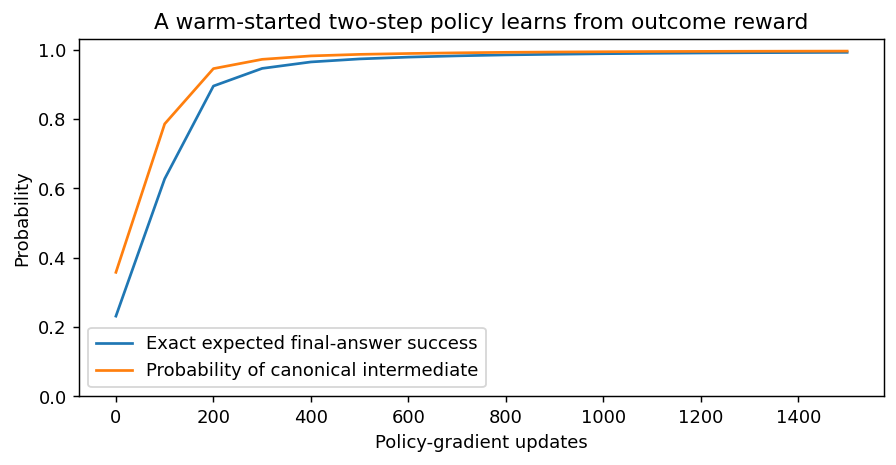

In [28]:
rl_rng=np.random.default_rng(2026)
L1=np.zeros((MOD,MOD,MOD));L2=np.zeros((MOD,MOD,MOD))
for a,b in itertools.product(range(MOD),repeat=2):L1[a,b,(a+b)%MOD]=0.8
for u,c in itertools.product(range(MOD),repeat=2):L2[u,c,(u+c)%MOD]=0.8

def policy_statistics(L1,L2):
    P1,P2=softmax_np(L1),softmax_np(L2)
    final_success=[];canonical_intermediate=[]
    for a,b,c in itertools.product(range(MOD),repeat=3):
        v=(a+b+c)%MOD
        final_success.append(P1[a,b]@P2[:,c,v])
        canonical_intermediate.append(P1[a,b,(a+b)%MOD])
    return float(np.mean(final_success)),float(np.mean(canonical_intermediate))
rl_history=[(0,*policy_statistics(L1,L2))]
RL_UPDATES=1500;RL_BATCH=256;RL_LR=4.0
for step in range(1,RL_UPDATES+1):
    a,b,c=rl_rng.integers(0,MOD,size=(3,RL_BATCH))
    P1,P2=softmax_np(L1),softmax_np(L2)
    p1=P1[a,b]
    u=(rl_rng.random(RL_BATCH)[:,None]>np.cumsum(p1,axis=-1)).sum(axis=-1)
    u=np.minimum(u,MOD-1)
    p2=P2[u,c]
    v=(rl_rng.random(RL_BATCH)[:,None]>np.cumsum(p2,axis=-1)).sum(axis=-1)
    v=np.minimum(v,MOD-1)
    truth=(a+b+c)%MOD
    reward=(v==truth).astype(float)
    # Exact expected success for each prompt; treated as fixed in this update.
    all_u=np.arange(MOD)[None,:]
    baseline=(p1*P2[all_u,c[:,None],truth[:,None]]).sum(axis=-1)
    adv=reward-baseline
    g1=np.zeros_like(L1);g2=np.zeros_like(L2)
    np.add.at(g1,(a,b),adv[:,None]*(np.eye(MOD)[u]-p1)/RL_BATCH)
    np.add.at(g2,(u,c),adv[:,None]*(np.eye(MOD)[v]-p2)/RL_BATCH)
    L1+=RL_LR*g1;L2+=RL_LR*g2
    if step%100==0:rl_history.append((step,*policy_statistics(L1,L2)))
rl_history=np.array(rl_history)
print('Initial final-success / canonical intermediate:',rl_history[0,1:])
print('Final final-success / canonical intermediate:',rl_history[-1,1:])
assert np.isfinite(L1).all() and np.isfinite(L2).all()
assert rl_history[-1,1]>rl_history[0,1]
fig,ax=plt.subplots(figsize=(7,3.7))
ax.plot(rl_history[:,0],rl_history[:,1],label='Exact expected final-answer success')
ax.plot(rl_history[:,0],rl_history[:,2],label='Probability of canonical intermediate')
ax.set(xlabel='Policy-gradient updates',ylabel='Probability',ylim=(0,1.03),title='A warm-started two-step policy learns from outcome reward')
ax.legend();plt.tight_layout();plt.show()


### What this reward-learning experiment establishes

It demonstrates a sequential policy, sampled actions, an environment reward, an independently computed baseline, gradient estimation, and parameter updates that improve expected reward. It does not demonstrate large-scale language-model training, GRPO performance, out-of-distribution reasoning, or emergent human-like reflection.

Outcome rewards do not uniquely identify the meaning of u. In fact, any consistent permutation of intermediate symbols can encode the same information if stage 2 learns the matching decoding. This is an **identifiability** issue: several internal representations can implement the same successful behaviour. Our warm start favours canonical arithmetic symbols, but reward alone does not logically require them.

This is why "the model got the answer right" and "the model used the exact explanation I expected" are different claims. Inspecting probability, interventions, and alternative successful representations is a more rigorous habit than reading an anthropomorphic narrative into every trace.


## 26. Accuracy, uncertainty intervals, and paired comparisons

For N evaluated tasks with correctness indicators $c_i\in\{0,1\}$, accuracy is
$$\hat p=\frac1N\sum_{i=1}^{N}c_i.$$
A point estimate does not say how uncertain it is. If N=20 and all examples succeed, that does not establish a true success probability of 100% on a larger population.

For independent Bernoulli tasks, a Wilson interval with normal quantile z is
$$\text{centre}=\frac{\hat p+z^2/(2N)}{1+z^2/N},\qquad
\text{half-width}=\frac{z}{1+z^2/N}\sqrt{\frac{\hat p(1-\hat p)}N+\frac{z^2}{4N^2}}.$$
Use z≈1.96 for an approximate 95% interval. Independence and representative sampling are assumptions. Benchmark items can share templates, violating the simple model. Repeated evaluation on the same tasks also does not create fresh independent evidence.

When comparing two systems on the same tasks, use a **paired** analysis. Resample task indices and preserve both systems' outcomes for each index. An unpaired bootstrap discards useful information about which problems were solved by both. With very small samples or boundary outcomes, bootstrap intervals can be unstable or degenerate. Report raw counts and inspect errors as well.


In [29]:
def wilson_interval(successes,n,z=1.96):
    phat=successes/n; denom=1+z*z/n
    center=(phat+z*z/(2*n))/denom
    half=z/denom*np.sqrt(phat*(1-phat)/n+z*z/(4*n*n))
    return center-half,center+half
for name in ['scratchpad','direct']:
    c=results[name]['test']['correct']
    print(name,'count:',int(c.sum()),'/',len(c),'Wilson interval:',np.round(wilson_interval(c.sum(),len(c)),3))
diff=results['scratchpad']['test']['correct'].astype(float)-results['direct']['test']['correct'].astype(float)
boot_rng=np.random.default_rng(123)
boot=diff[boot_rng.integers(0,len(diff),size=(5000,len(diff)))].mean(axis=1)
print('Paired accuracy difference:',diff.mean(),'bootstrap interval:',np.quantile(boot,[0.025,0.975]))
print('One training seed is not a seed-robust comparison. Repeat complete runs for that claim.')


scratchpad count: 20 / 20 Wilson interval: [0.839 1.   ]
direct count: 0 / 20 Wilson interval: [-0.     0.161]
Paired accuracy difference: 1.0 bootstrap interval: [1. 1.]
One training seed is not a seed-robust comparison. Repeat complete runs for that claim.


## 27. Generalisation, robustness, and distribution shift

These terms refer to different tests:

* **Held-out instance generalisation:** new triples drawn from the same bounded task space.
* **Robustness:** changing wording or irrelevant details while preserving the intended task.
* **Compositional generalisation:** new combinations of familiar rules or components.
* **Length generalisation:** more required steps or longer inputs than training.
* **Distribution shift:** a change in the input or task distribution, including unseen symbols or new environments.

Our tiny model has no natural-language instruction-following training. It would be misleading to expect it to understand an arbitrary English paraphrase. We can, however, test a clear shift: supply digits 5–9 even though training inputs used 0–4. Those tokens exist in the vocabulary but their input embeddings did not receive digit-specific training examples. The same modulo-5 arithmetic rule still defines the answers.

A failure establishes a limitation of this trained model under this shift. It does not show arithmetic is impossible for Transformers. A success would also need careful analysis, because the task remains narrow.

For a robust evaluation design, specify the transformation before inspecting results. If you select only transformations that make a model look bad—or only ones that make it look good—you are measuring selection bias as well as capability.


In [30]:
ood_rng=np.random.default_rng(83)
ood_triples=[tuple(map(int,row)) for row in ood_rng.integers(5,10,size=(30,3))]
ood_result=evaluate_generated(scratch_model,ood_triples,True)
print('In-domain test accuracy:',results['scratchpad']['test']['final_accuracy'])
print('Unseen-input-digit accuracy:',ood_result['final_accuracy'])
for t,out in zip(ood_triples[:5],ood_result['outputs'][:5]):
    print(prompt_for(t),out,'expected',completion_for(t))
# Exact rule-based baseline solves both domains because the rule is programmed explicitly.
assert all(answer_for(t)==int(completion_for(t)[-2]) for t in ood_triples)


In-domain test accuracy: 1.0
Unseen-input-digit accuracy: 0.26666666666666666
8+6+7= 3>4# expected 4>1#
5+6+8= 2>0# expected 1>4#
6+6+7= 3>4# expected 2>4#
6+7+6= 3>4# expected 3>4#
5+9+7= 2>2# expected 4>1#


### Dataset contamination and benchmark saturation

A benchmark can cease to measure novelty if examples or close variants enter training. Public test questions may be copied into tutorials, synthetic datasets, or evaluation tuning loops. Contamination is broader than exact string duplication.

Private or newly generated tasks help but are not magic: a model can still exploit recurring templates or weak scoring. Conversely, a model can genuinely generalise from related examples; overlap of concepts is not automatically cheating. The scientific question is what kind of generalisation the test actually isolates.

A useful report includes data provenance, split policy, deduplication method, prompt format, tools, sampling, compute budget, parser, scoring rules, and uncertainty. Benchmark versions are not interchangeable. A high score is evidence on a specified test, not a general intelligence certificate.


## 28. Calibration: probability should mean something

A calibrated confidence of 0.8 means that, among sufficiently many comparable predictions given confidence near 0.8, approximately 80% are correct. Calibration is a property of a prediction system on a distribution, not a guarantee for each individual example.

For binary outcomes, the **Brier score** is
$$\mathrm{Brier}=\frac1N\sum_i(q_i-c_i)^2,$$
where $q_i$ is predicted success probability and $c_i$ is actual correctness. Lower is better, but Brier reflects both calibration and discrimination; it is not a pure calibration metric.

A reliability diagram bins confidences and compares average confidence with observed accuracy. **Expected Calibration Error (ECE)** is a common summary:
$$\mathrm{ECE}=\sum_{b=1}^{B}\frac{|S_b|}{N}\left|\mathrm{accuracy}(S_b)-\mathrm{confidence}(S_b)\right|.$$
$S_b$ is a bin of examples, B is the number of bins. The estimate depends on binning and can be noisy. Empty bins should be omitted. Do not treat a tiny dataset's ECE as a stable model property.

**Tricky issue:** multiplying probabilities of one selected text does not give the probability of a semantic answer if many texts express that answer. Our finite grammar lets us sum over all valid scratchpad paths, rather than equating one wording with the entire answer event.


Marginal-answer selector accuracy: 1.0 binary confidence Brier: 0.018946713611267048 ECE: 0.052091289824431515
Reliability bins: mean confidence, accuracy, count: [(np.float64(0.510732202260809), np.float64(1.0), 1), (np.float64(0.6708937053207867), np.float64(1.0), 1), (np.float64(0.987586016440543), np.float64(1.0), 18)]


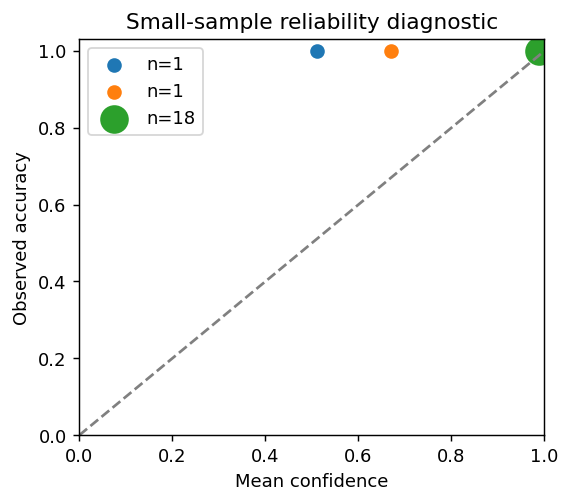

In [31]:
def finite_answer_distribution(net,triples):
    # Unrestricted model mass over the 25 canonical-format completions u>v#.
    # Every other fixed-length completion is assigned to an invalid category.
    dist=np.zeros((len(triples),MOD+1))
    for i,triple in enumerate(triples):
        prompt=prompt_for(triple)
        first=softmax_np(net(np.array([encode(prompt)])).data[0,-1])
        for u in range(MOD):
            prefix=prompt+str(u)
            sep_prob=softmax_np(net(np.array([encode(prefix)])).data[0,-1])[stoi['>']]
            v_probs=softmax_np(net(np.array([encode(prefix+'>')])).data[0,-1])
            for v in range(MOD):
                stop_prob=softmax_np(net(np.array([encode(prefix+'>'+str(v))])).data[0,-1])[stoi['#']]
                dist[i,v]+=first[stoi[str(u)]]*sep_prob*v_probs[stoi[str(v)]]*stop_prob
        dist[i,-1]=max(0.,1.-dist[i,:MOD].sum())
    return dist
answer_dist=finite_answer_distribution(scratch_model,test_triples)
assert np.allclose(answer_dist.sum(axis=1),1.)
pred=answer_dist.argmax(axis=1)
confidence=answer_dist.max(axis=1)
correct=(pred==np.array([answer_for(t) for t in test_triples])).astype(float)
brier=float(np.mean((confidence-correct)**2))
# The prediction rule above is marginal answer selection, not greedy text generation.
bins=np.linspace(0,1,6); points=[];ece=0.
for lo,hi in zip(bins[:-1],bins[1:]):
    selected=(confidence>=lo)&((confidence<hi) if hi<1 else (confidence<=hi))
    if selected.any():
        conf=confidence[selected].mean();acc=correct[selected].mean()
        ece+=selected.mean()*abs(conf-acc);points.append((conf,acc,int(selected.sum())))
print('Marginal-answer selector accuracy:',correct.mean(),'binary confidence Brier:',brier,'ECE:',ece)
print('Reliability bins: mean confidence, accuracy, count:',points)
fig,ax=plt.subplots(figsize=(4.5,4))
ax.plot([0,1],[0,1],'--',color='grey')
for conf,acc,n in points:ax.scatter(conf,acc,s=40+10*n,label=f'n={n}')
ax.set(xlim=(0,1),ylim=(0,1.03),xlabel='Mean confidence',ylabel='Observed accuracy',title='Small-sample reliability diagnostic')
ax.legend();plt.tight_layout();plt.show()


### Read that calibration experiment carefully

We chose the answer with the largest **marginal probability**, summing over every valid intermediate u. This can differ from the final digit in the single greedy-generated trace. We therefore report it as a different selector. If the most probable category is invalid, it is treated as a failed answer.

The probabilities correspond to a fixed-length character protocol. They are not natural-language confidence estimates, and the sample size is only 20. The exercise teaches how to define the event being calibrated, preserve probability mass, and avoid confusing token confidence with semantic correctness.

For deployment, calibration must be checked on the target distribution and refreshed after model, prompt, tool, or task changes. Abstention can improve accepted-answer accuracy while reducing coverage. That trade-off should be explicit.


In [32]:
print('Threshold | coverage | accuracy among accepted')
for threshold in [0.,0.5,0.7,0.9,0.99]:
    accepted=(confidence>=threshold)&(pred<MOD)
    selective_acc=float(correct[accepted].mean()) if accepted.any() else float('nan')
    print(threshold,round(float(accepted.mean()),3),selective_acc)


Threshold | coverage | accuracy among accepted
0.0 1.0 1.0
0.5 1.0 1.0
0.7 0.9 1.0
0.9 0.85 1.0
0.99 0.75 1.0


## 29. Faithfulness, explanations, and mechanistic evidence

An explanation is **faithful** when it accurately reflects the relevant influences on the answer under the definition being tested. Correctness and faithfulness are different axes. A correct explanation may be generated after an answer was chosen for another reason; a faithful account can describe a mistaken method.

Several evidence levels help:

1. **Text inspection:** identify valid or invalid steps. This checks the trace's content.
2. **Behavioural perturbation:** change a premise, hint, or intermediate token and observe effects.
3. **Controlled interventions:** alter a specific internal activation or pathway while preserving appropriate controls.
4. **Mechanistic models:** formulate a computational hypothesis and test predictions on fresh cases.

None is automatically complete. Changing a token can shift the input distribution. Altering an activation can damage many functions at once. A probe that predicts the answer from hidden states establishes decodability, not that the model uses that information causally. An attention plot can suggest a hypothesis without proving it.

Anthropic's hint-based studies showed that tested reasoning models sometimes changed answers in response to hints without acknowledging that influence in their traces. The tasks, models, and hint types limit the conclusion. It is not evidence that every reasoning trace is useless or that every model deliberately lies.

Source: *Reasoning Models Don't Always Say What They Think* (2025), https://www.anthropic.com/research/reasoning-models-dont-say-think.


## 30. A reproducible experiment report

A useful report separates **observations**, **interpretations**, and **unresolved questions**. "Scratchpad test accuracy was 19/20" is an observation. "This model learned a reusable decomposition" is an interpretation requiring more evidence. "Will it generalise to longer sums?" is an unresolved question.

The report below records the actual run. It does not change the experiment after seeing outcomes or silently remove failed examples. Keep the seed and compute accounting when publishing a chart.

**Minimum reporting checklist:** task definition; input and output grammar; training/validation/test split; model size; objective; seed; optimisation budget; free-generation decoding; exact scoring rule; counts and intervals; cost; baseline; distribution shifts; and limitations. If one component uses an exact algorithm, identify it. If one metric uses oracle selection, label it.


In [33]:
experiment_report={
    'task':'three digits in 0..4; sum modulo 5',
    'seed':7,'model_parameters':scratch_model.count_params(),
    'train_examples':len(train_triples),'validation_examples':len(val_triples),'test_examples':len(test_triples),
    'updates_per_model':TRAIN_STEPS,'decoding':'greedy, fixed-length protocol',
    'scratchpad_test_accuracy':results['scratchpad']['test']['final_accuracy'],
    'direct_test_accuracy':results['direct']['test']['final_accuracy'],
    'scratchpad_cost':scratch_cost,'direct_cost':direct_cost,
    'ood_digit_accuracy':ood_result['final_accuracy'],
    'limitations':['one seed','tiny synthetic task','unequal processed tokens',
                   'no large-scale pretraining','no evidence about human-like thought']}
print(json.dumps(experiment_report,indent=2))


{
  "task": "three digits in 0..4; sum modulo 5",
  "seed": 7,
  "model_parameters": 10608,
  "train_examples": 90,
  "validation_examples": 15,
  "test_examples": 20,
  "updates_per_model": 1000,
  "decoding": "greedy, fixed-length protocol",
  "scratchpad_test_accuracy": 1.0,
  "direct_test_accuracy": 0.0,
  "scratchpad_cost": {
    "seconds": 4.209674419999828,
    "input_tokens": 216000,
    "supervised_tokens": 96000
  },
  "direct_cost": {
    "seconds": 3.673900897999829,
    "input_tokens": 168000,
    "supervised_tokens": 48000
  },
  "ood_digit_accuracy": 0.26666666666666666,
  "limitations": [
    "one seed",
    "tiny synthetic task",
    "unequal processed tokens",
    "no large-scale pretraining",
    "no evidence about human-like thought"
  ]
}


## 31. Advanced mechanisms: latent computation, recurrence, and distillation

### 31.1 Language-space versus latent-space reasoning

In language-space reasoning, a hidden state is projected into vocabulary logits, a token is selected, and that token is embedded for the next step. Abstractly:
$$h_t\xrightarrow{W_{out}}z_t\xrightarrow{\text{selection}}y_t\xrightarrow{E}e_{y_t}.$$
The projection and discrete selection constrain the information explicitly carried by that token. The full context and model state can retain other information, so it would be wrong to say the entire model's memory is reduced to one token.

A latent recurrence can instead pass a continuous state:
$$h_{t+1}=F_\theta(h_t,x).$$
$h_t\in\mathbb R^d$ is an internal representation, x is input information, and the same function $F_\theta$ may be reused. "Latent" means not directly observed as task-level text; it does not mean mystical, conscious, or automatically interpretable.

Coconut experiments reuse a hidden representation as a subsequent input rather than decoding each intermediate step into text. Its results on selected reasoning tasks motivate further study, not a claim that every proprietary model works this way. Native hidden activations in an ordinary Transformer and a specially trained multi-step latent recurrence are also different things.

The benefit of a continuous state is potential flexibility and efficiency. The challenge is training, checking, and controlling the computation when intermediate states do not have explicit semantic labels. A vector can carry many alternatives, but that fact alone does not prove that it executes a complete breadth-first search.

Source: Hao et al., *Training Large Language Models to Reason in a Continuous Latent Space*, https://arxiv.org/abs/2412.06769.

### 31.2 More iterations are not automatically better

Repeated application of a function can converge, oscillate, or diverge. Consider an elementary iterative solver:
$$h_{t+1}=h_t-\eta(h_t-a)=(1-\eta)h_t+\eta a.$$
The target is a. Subtracting a gives $h_{t+1}-a=(1-\eta)(h_t-a)$. Therefore the error after t steps is $(1-\eta)^t(h_0-a)$. Convergence requires $|1-\eta|<1$, or $0<\eta<2$.

This is not an LLM, but it establishes a useful mathematical warning: extra recurrent computation helps only if its dynamics are appropriate. An arbitrary reasoning loop can reinforce errors or become unstable. Training a useful stopping decision is part of the challenge.


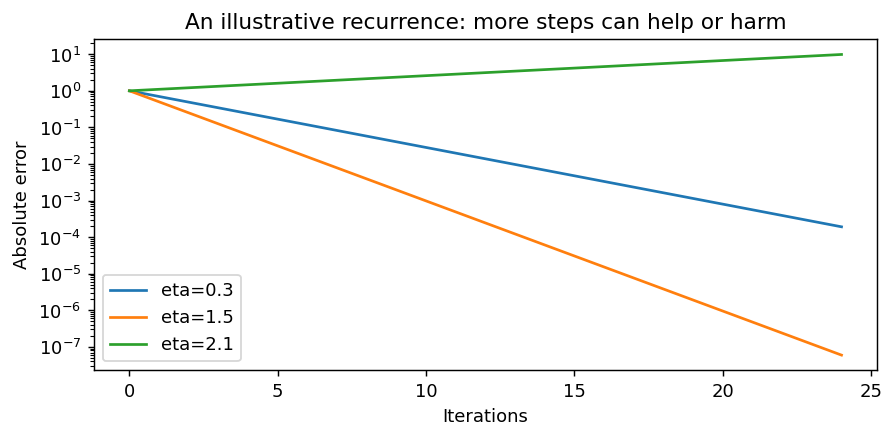

In [34]:
fig,ax=plt.subplots(figsize=(7,3.5))
for eta in [0.3,1.5,2.1]:
    h=0.;target=1.;errors=[]
    for _ in range(25):
        errors.append(abs(h-target));h=h-eta*(h-target)
    ax.plot(errors,label=f'eta={eta}')
ax.set(xlabel='Iterations',ylabel='Absolute error',yscale='log',title='An illustrative recurrence: more steps can help or harm')
ax.legend();plt.tight_layout();plt.show()


### 31.3 Distillation: transfer distributions or demonstrations

A teacher distribution q and student distribution p can be matched using
$$L_{distill}=D_{KL}(q\|p)=\sum_iq_i\log\frac{q_i}{p_i}.$$
q is held fixed; only p's parameters are updated. Because $\sum_iq_i\log q_i$ does not depend on the student, minimising this KL is equivalent to minimising soft-target cross-entropy $-\sum_iq_i\log p_i$.

With temperature $\tau$, both teacher and student logits may be divided by $\tau$. Some formulations multiply the resulting loss by $\tau^2$ to compensate for gradient scaling. Exact conventions matter; copying the symbol without its training setup is insufficient.

**Sequence distillation** can instead use teacher-generated solutions as ordinary supervised examples. It does not require access to the teacher's token probabilities. A student can learn useful patterns but also inherit errors, stylistic quirks, and dataset biases. Filtering requires a verifier whose own limitations must be measured.

A shorter student response after distillation does not demonstrate that the original reasoning has been preserved perfectly. Check answer quality, robustness, intermediate dependencies, and cost.


In [35]:
teacher=np.array([0.7,0.2,0.1]);student_logits=np.zeros(3)
distill_losses=[]
for _ in range(150):
    student=softmax_np(student_logits)
    distill_losses.append(float(-np.sum(teacher*np.log(student))))
    # Gradient of soft-target cross-entropy wrt logits is p-q.
    student_logits-=0.2*(student-teacher)
print('Teacher:',teacher,'Student after distillation:',softmax_np(student_logits))
assert np.max(abs(softmax_np(student_logits)-teacher))<0.02


Teacher: [0.7 0.2 0.1] Student after distillation: [0.6996 0.1992 0.1012]


### 31.4 Architecture and reasoning are separate design axes

A dense feed-forward layer applies the same parameterised transformation to every token. A sparse Mixture of Experts can route tokens to selected transformations:
$$f(h)=\sum_{e\in\mathcal S(h)}g_e(h)f_e(h).$$
$f_e$ is expert e, $g_e$ its routing weight, and $\mathcal S(h)$ the selected subset. Experts are numerical subnetworks; their labels do not guarantee neatly separated human domains such as "mathematics expert" and "history expert." Sparse activation changes capacity and compute accounting, not logical soundness.

State-space models such as Mamba use a different sequence-processing approach. Recurrent state, attention, external memory, and hybrid designs offer different trade-offs. Their reasoning ability must be evaluated under controlled data, training, and compute—not inferred from architecture names.

Architectural changes, learned reasoning strategies, and external workflows can interact. A strong benchmark result does not identify which component caused the improvement unless we ablate the components. An **ablation** removes or changes one component while keeping the relevant comparison conditions controlled.


## 32. The research frontier and the questions that remain open

### 32.1 Does reward training create new capabilities or expose existing ones?

Changing parameters can improve which responses a model generates. A deeper question is whether training teaches new reusable algorithms, increases probability on already available successful paths, or does some mixture of both.

Large-k pass@k comparisons can probe the set of accessible successful responses. But finite sampling cannot establish that a response has zero probability, and changes in prompting, temperature, and compute affect the measurement. Evidence from particular model families does not settle the question for every training regime.

Yue et al. investigate this issue in *Does Reinforcement Learning Really Incentivize Reasoning Capacity in LLMs Beyond the Base Model?* (2025), https://arxiv.org/abs/2504.13837. Read its experimental conditions and limitations alongside strong capability claims. Treat this as an empirical debate, not a theorem that RL can never learn.

### 32.2 Verification when there is no answer key

Mathematics and code offer unusually useful feedback. Business strategy, scientific hypotheses, ethical questions, and many causal questions lack cheap complete verifiers. Better generation without better checking can create a larger pile of plausible mistakes. Research directions include tools, formalisation, expert feedback, uncertainty-aware selection, and evaluation on actual downstream outcomes.

### 32.3 Long-horizon reasoning

Long tasks require preserving goals, checking assumptions, handling changing information, and recovering from errors. A larger context window is not equivalent to reliable working memory. External state, durable workflows, structured plans, and checkpoints can help, but those are system capabilities that must be evaluated as such.

### 32.4 Adaptively spending computation

A model can waste effort on easy tasks or stop too early on hard ones. Useful signals might include verifier feedback, disagreement among candidates, uncertainty estimates, and learned difficulty predictors. Disagreement does not always imply productive diversity; several diverse-looking traces can share the same wrong premise.

### 32.5 Public milestones versus unknown proprietary details

OpenAI's o1 report documents improvements with reinforcement learning and inference-time computation. DeepSeek-R1 makes a concrete training account available. The s1 work studies budget forcing on a specially trained model; appending "wait" to arbitrary text is not a universal reasoning upgrade.

More recent official reports include DeepMind's Aletheia generation–verification–revision work (February 2026), OpenAI's discrete-geometry conjecture result (May 2026), Anthropic's Fermat formalisation report (September 2026), and the Conceptual Reasoning Index (August 2026). Each has a different task and verification protocol. Formalising a known theorem is different from discovering a new proof; resolving a particular conjecture is different from solving every related open problem.

These examples motivate careful study rather than a model ranking. Full proprietary training recipes and all internal mechanisms are not public. This notebook does not fill missing disclosures with guesses. Follow the linked primary reports in Chapter 34 for dated scope and supporting material.


## 33. Capstone: design an investigation that could change your mind

A useful research question is narrow enough that contrary evidence is possible. "Are LLMs intelligent?" is too broad for this notebook. Better questions include:

1. Does an explicit intermediate target improve held-out accuracy under equal **processed-token** budgets on this arithmetic task?
2. Does the final prediction causally depend on the intermediate digit?
3. Does majority voting help when errors are systematic rather than dispersed?
4. Does outcome-only training preserve the expected interpretation of intermediate symbols?
5. Does a calibrated abstention policy transfer to an unseen-digit distribution?

For each, write your hypothesis **before** running an extended experiment. Specify the dataset, baseline, budget, metric, uncertainty, and falsifying outcome. Keep a locked final test split; use validation for choices.

### A concrete experiment plan

**Hypothesis:** scratchpad supervision improves compositional generalisation at comparable training cost. **Baseline:** direct-answer Transformer with identical width and depth. **Budget:** choose a processed-token budget, adjusting update counts to account for different sequence lengths; also report time and parameter count. **Replicates:** at least several independent initialisation and split seeds. **Outcomes:** exact final accuracy, exact trace accuracy, malformed-output frequency, and paired task-level differences. **Stress tests:** unseen digit ranges and a separately designed longer-input task. **Failure criterion:** the predicted advantage is absent or does not survive the declared checks.

Changing model size, training length, prompt format, and dataset all at once would make the comparison hard to interpret. There is no shame in a negative result; it can expose which assumptions were wrong.

### A model-agnostic evaluation interface

The following harness accepts any response-producing function. Here it calls our local model. Later you can replace that function with a local open model, keeping task definitions and scorers unchanged. Do not mix results across model versions without recording the change. No external service is called by this notebook.


In [36]:
def evaluate_callable(solve_fn,triples,metadata):
    records=[]
    for triple in triples:
        start=time.perf_counter()
        text=solve_fn(triple)
        elapsed=time.perf_counter()-start
        verdict=verify_arithmetic(triple,text)
        records.append({'input':prompt_for(triple),'response':text,'seconds':elapsed,**verdict})
    return {'metadata':metadata,'records':records,
            'final_accuracy':float(np.mean([r['final'] for r in records])),
            'exact_trace_accuracy':float(np.mean([r['all'] for r in records])),
            'mean_seconds':float(np.mean([r['seconds'] for r in records]))}
capstone=evaluate_callable(lambda t:generate_batch(scratch_model,[t],True)[0],test_triples,
                          {'model':'local tiny Transformer','seed':7,'temperature':'greedy','tools':False})
print({k:v for k,v in capstone.items() if k!='records'})
assert len(capstone['records'])==len(test_triples)


{'metadata': {'model': 'local tiny Transformer', 'seed': 7, 'temperature': 'greedy', 'tools': False}, 'final_accuracy': 1.0, 'exact_trace_accuracy': 1.0, 'mean_seconds': 0.003747696699997505}


## 34. References and a study route

These are study resources, not implied endorsements of every claim in a paper. Read methods, versions, and limitations. Paper links are freely accessible. Books may require purchase or library access; companion code is often free. Start with conceptual resources before attempting full derivations.

### First pass: accessible explanation

* **Andrej Karpathy — Deep Dive into LLMs like ChatGPT.** A free video covering pretraining, supervised training, intermediate computation, and reinforcement learning. https://www.youtube.com/watch?v=7xTGNNLPyMI
* **OpenAI — Learning to Reason with LLMs (2024).** A readable primary report on o1's training and inference-time scaling. https://openai.com/index/learning-to-reason-with-llms/
* **Jay Alammar and Maarten Grootendorst — Hands-On Large Language Models.** Visual foundations for embeddings, Transformers, and practical language-model use; not a complete account of the latest reasoning research. https://www.llm-book.com/

### Neural and optimisation foundations

* **Vaswani et al. — Attention Is All You Need (2017).** The original Transformer architecture; compare its encoder–decoder design with our decoder-only toy. https://arxiv.org/abs/1706.03762
* **Schulman et al. — Proximal Policy Optimization Algorithms (2017).** The source for PPO's clipped surrogate; read after the policy-gradient derivation. https://arxiv.org/abs/1707.06347
* **Sutton and Barto — Reinforcement Learning: An Introduction, second edition.** Broad foundations including value functions, temporal-difference learning, and policy gradients; the authors provide study material and a free online book link. http://incompleteideas.net/book/the-book-2nd.html
* **Russell and Norvig — Artificial Intelligence: A Modern Approach.** Search, logic, probability, planning, and causal reasoning beyond language modelling. https://aima.eecs.berkeley.edu/

### Core reasoning papers

* **Wei et al. — Chain-of-Thought Prompting Elicits Reasoning in Large Language Models (2022).** Intermediate demonstrations and task-dependent improvements. https://arxiv.org/abs/2201.11903
* **Wang et al. — Self-Consistency Improves Chain of Thought Reasoning in Language Models (2022).** Sample multiple solution paths and aggregate answers. https://arxiv.org/abs/2203.11171
* **Yao et al. — Tree of Thoughts (2023).** Search over intermediate text states using proposal and evaluation. https://arxiv.org/abs/2305.10601
* **Lightman et al. — Let's Verify Step by Step (2023).** Process supervision and step-level feedback. https://arxiv.org/abs/2305.20050
* **Shao et al. — DeepSeekMath (2024).** Mathematical pretraining, post-training, and GRPO. https://arxiv.org/abs/2402.03300
* **DeepSeek-AI — DeepSeek-R1 (2025).** A public reasoning-training pipeline including RL and distillation. https://arxiv.org/abs/2501.12948
* **Snell et al. — Scaling LLM Test-Time Compute Optimally Can Be More Effective than Scaling Model Parameters (2024).** Compute allocation and task-dependent inference strategies. https://arxiv.org/abs/2408.03314
* **Muennighoff et al. — s1: Simple Test-Time Scaling (2025).** A controlled study of reasoning training and budget forcing. https://arxiv.org/abs/2501.19393
* **Hao et al. — Training Large Language Models to Reason in a Continuous Latent Space (first released 2024).** Coconut and latent intermediate representations. https://arxiv.org/abs/2412.06769

### Evaluation, interpretation, and debate

* **Mirzadeh et al. — GSM-Symbolic (2024; ICLR 2025).** Controlled variations of mathematical problems and robustness questions. https://arxiv.org/abs/2410.05229
* **Rein et al. — GPQA (2023).** Expert science questions combining specialist knowledge and reasoning. https://arxiv.org/abs/2311.12022
* **ARC Prize — ARC-AGI-2.** Abstract grid reasoning, interacting rules, and explicit cost reporting. https://arcprize.org/arc-agi/2
* **Anthropic — Reasoning Models Don't Always Say What They Think (2025).** Hint-based tests of reasoning-trace faithfulness and their limitations. https://www.anthropic.com/research/reasoning-models-dont-say-think
* **Yue et al. — Does Reinforcement Learning Really Incentivize Reasoning Capacity in LLMs Beyond the Base Model? (2025).** Large-k sampling comparisons that challenge simple interpretations of RL gains. https://arxiv.org/abs/2504.13837
* **Redwood Research and Anthropic — Conceptual Reasoning Index (2026).** Evaluation beyond tasks with simple answer keys. https://alignment.anthropic.com/2026/conceptual-reasoning-index/

### Dated frontier reports

* **Google DeepMind — Accelerating Mathematical and Scientific Discovery with Gemini Deep Think (February 2026).** Research-level generation, verification, revision, and expert collaboration. https://deepmind.google/blog/accelerating-mathematical-and-scientific-discovery-with-gemini-deep-think/
* **OpenAI — An OpenAI Model Has Disproved a Central Conjecture in Discrete Geometry (May 2026).** A specific mathematical discovery and external proof checking. https://openai.com/index/model-disproves-discrete-geometry-conjecture/
* **Anthropic — Formalizing Fermat's Last Theorem (September 2026).** A large formalisation task checked in Lean, distinct from discovering the original theorem's proof. https://www.anthropic.com/research/formalizing-fermats-last-theorem

### When you want to build more

* **Sebastian Raschka — Build a Reasoning Model (From Scratch).** Evaluation, inference-time scaling, reinforcement learning, and distillation with Python/PyTorch; companion code makes a useful next step after this CPU notebook. https://sebastianraschka.com/reasoning-from-scratch/
* **Stanford CS336 — Language Modeling from Scratch.** Free lectures and assignments; especially relevant are alignment and reasoning RL. https://cs336.stanford.edu/
* **Stanford CS336, 2025 Lecture 16 — Alignment: RL 1.** More technical reinforcement-learning foundations. https://www.youtube.com/watch?v=46f2QTDB08Q
* **Stanford CS336, 2025 Lecture 17 — Alignment: RL 2.** Continues into language-model reward training. https://www.youtube.com/watch?v=JdGFdViaOJk

**Suggested order:** Karpathy → Chapters 1–16 here → Wei and Wang → Chapters 17–25 → DeepSeekMath/R1 → Chapters 26–33 → faithfulness and evaluation papers → Raschka or Stanford for larger-model engineering. Return to Sutton and Barto when value functions and temporal credit assignment become the bottleneck.


## 35. Exercises with worked guidance

### Exercise 1 — Conditional probability
A two-step path has first-step success probability 0.7 and second-step success probability 0.8 conditional on the first being correct. What is the path success probability? Does this establish total task success?

**Answer:** $0.7\times0.8=0.56$ for this path. Alternative successful paths can add probability; incorrect earlier steps might also be corrected later. The task probability needs the full event definition.

### Exercise 2 — Vocabulary loss
The correct token has probability 0.2. Compute its negative log-likelihood. What changes if it rises to 0.8?

**Answer:** $-\log0.2\approx1.609$, falling to $-\log0.8\approx0.223$. The objective rewards increased probability on the target, not a guaranteed correct greedy rollout.

### Exercise 3 — Shapes
A batch of 16 prompts has length 9 and width 24. What are the attention-score and vocabulary-logit shapes for vocabulary size 15?

**Answer:** one-head scores $(16,9,9)$; logits $(16,9,15)$. More heads introduce a head axis, such as $(16,H,9,9)$.

### Exercise 4 — Causality
Why is a low loss suspicious if future completion tokens are visible when predicting the current token?

**Answer:** the model may read the target or its consequences instead of learning a predictive procedure. Train-time information unavailable at generation invalidates the claimed deployment measurement.

### Exercise 5 — Sampling and selection
With p=0.2 and ten independent attempts, compute the probability that at least one succeeds. Is majority-vote accuracy necessarily that high?

**Answer:** $1-0.8^{10}\approx0.893$. No: majority voting may repeatedly select a common wrong answer. Any-success uses a success test; voting uses answer frequency.

### Exercise 6 — Baselines
Why must an unbiased REINFORCE baseline be independent of the sampled action conditional on the state or prompt?

**Answer:** only then does its expected score-function contribution cancel as $b\nabla\sum_a\pi(a)=0$. An action-dependent baseline generally adds a nonzero term unless a correction is included.

### Exercise 7 — Intermediate symbols
Could the two-step reward policy learn a successful non-arithmetic encoding of u?

**Answer:** yes. A consistent permutation of intermediate labels preserves the information required by stage 2. Outcome reward alone need not identify the canonical interpretation.

### Exercise 8 — Calibration
If all 20 test predictions are correct and confidence is 0.99, have you established calibration?

**Answer:** no. The sample is small, confidence occupies a narrow range, and the distribution may not represent deployment. Calibration needs enough observations across relevant confidence levels and tasks.

### Exercise 9 — Experimental fairness
Why is equal optimiser-update count not equal compute for direct versus scratchpad training?

**Answer:** sequence lengths differ; attention, projections, and supervised-token counts therefore differ. State the budget and report cost rather than treating updates as universal compute units.

### Exercise 10 — Open project
Change exactly one feature: training split, seed, model width, update budget, or supervised format. Record the hypothesis first. Explain the changed result using counts, costs, and errors. Do not merely choose whichever run produces the nicest plot.


# Mathematical appendices: move from using equations to deriving them

These appendices deepen the earlier chapters. You can read the main story first and return here. They are included because the most important confusion often lives between two apparently simple equations.

## Appendix A. Derive the softmax cross-entropy gradient

For logits z, define $S=\sum_k e^{z_k}$ and $p_i=e^{z_i}/S$. Differentiating the quotient gives
$$\frac{\partial p_i}{\partial z_j}=p_i(\delta_{ij}-p_j).$$
The Kronecker delta $\delta_{ij}$ is 1 when i=j and 0 otherwise. On the diagonal, the derivative is $p_i(1-p_i)$: increasing a logit increases its own probability. Off the diagonal it is $-p_ip_j$: increasing one logit takes mass from others.

For a one-hot target t, with $t_k=1$ for the correct class and zero otherwise,
$$L=-\sum_i t_i\log p_i=-z_k+\log\sum_j e^{z_j}.$$
Differentiate the right-hand expression:
$$\frac{\partial L}{\partial z_j}=p_j-t_j.$$
This compact result explains the optimisation direction. For the correct class, the derivative is negative unless p=1, so gradient descent raises its logit. For incorrect classes it is positive, so descent lowers them.

For a soft target q with $\sum_iq_i=1$, replace t by q and obtain the distillation derivative $p-q$. This is the derivative implemented in Chapter 31.

**Worked numbers:** suppose $p=(0.6,0.3,0.1)$ and the correct class is the second. The gradient is $(0.6,-0.7,0.1)$. With learning rate 0.1, subtracting it changes logits by $(-0.06,+0.07,-0.01)$. This changes probabilities indirectly through softmax; it is not a direct assignment of those probability changes.


In [37]:
z=np.log(np.array([0.6,0.3,0.1]))
target=np.array([0.,1.,0.])
p0=softmax_np(z);gradient=p0-target
z_new=z-0.1*gradient
print('Before:',p0,'gradient:',gradient,'After:',softmax_np(z_new))
assert softmax_np(z_new)[1]>p0[1]
# Jacobian sums to zero along each logit column because total probability stays 1.
Jac=np.diag(p0)-np.outer(p0,p0)
print('Softmax Jacobian:\n',Jac)
assert np.allclose(Jac.sum(axis=0),0)


Before: [0.6 0.3 0.1] gradient: [ 0.6 -0.7  0.1] After: [0.5732 0.3264 0.1004]
Softmax Jacobian:
 [[ 0.24 -0.18 -0.06]
 [-0.18  0.21 -0.03]
 [-0.06 -0.03  0.09]]


## Appendix B. Backpropagate through attention by hand

We earlier relied on automatic differentiation. Here is the underlying matrix calculus for one head without batch axes:
$$S=QK^\top/\sqrt d+M,\quad A=\operatorname{softmax}_{row}(S),\quad O=AV.$$
Let $G=\partial L/\partial O$ be the upstream gradient, with the same shape as O.

**Step 1: differentiate the weighted combination.**
$$\frac{\partial L}{\partial V}=A^\top G,\qquad
\frac{\partial L}{\partial A}=GV^\top.$$
The first collects how each value vector contributed to every output. The second asks how changing an attention weight would alter the loss.

**Step 2: differentiate row-wise softmax.** If $B=\partial L/\partial A$, the score gradient is
$$D_{ij}=A_{ij}\left(B_{ij}-\sum_kA_{ik}B_{ik}\right).$$
This is the softmax Jacobian-vector product without materialising a full Jacobian for every row. The weighted row average subtracts the effect shared by all logits. Prohibited positions have zero attention and therefore zero score gradient in the ideal masked case.

**Step 3: differentiate the query/key dot products.**
$$\frac{\partial L}{\partial Q}=DK/\sqrt d,\qquad
\frac{\partial L}{\partial K}=D^\top Q/\sqrt d.$$
Then differentiate Q=$HW_Q$, K=$HW_K$, and V=$HW_V$ using the matrix-product rule. Their contributions to H must be added because H feeds three paths.

Shapes are a valuable error detector. If Q is $(T,d)$, D is $(T,T)$, and K is $(T,d)$, then DK is $(T,d)$ as required. An apparently plausible formula with mismatched dimensions is wrong before any training begins.


In [38]:
grad_rng=np.random.default_rng(77)
q=Tensor(grad_rng.normal(size=(3,2)))
k=Tensor(grad_rng.normal(size=(3,2)))
v=Tensor(grad_rng.normal(size=(3,2)))
upstream=grad_rng.normal(size=(3,2))
mask=np.where(np.triu(np.ones((3,3),dtype=bool),1),-1e9,0.)
att=softmax_t(q@k.transpose((1,0))/np.sqrt(2)+mask)
out=att@v
loss=(out*upstream).sum();loss.backward()
A=att.data;B=upstream@v.data.T
D=A*(B-(A*B).sum(axis=-1,keepdims=True))
manual_q=D@k.data/np.sqrt(2)
manual_k=D.T@q.data/np.sqrt(2)
manual_v=A.T@upstream
print('Attention derivative errors:',np.max(abs(q.grad-manual_q)),np.max(abs(k.grad-manual_k)),np.max(abs(v.grad-manual_v)))
assert np.allclose(q.grad,manual_q) and np.allclose(k.grad,manual_k) and np.allclose(v.grad,manual_v)


Attention derivative errors: 4.440892098500626e-16 4.440892098500626e-16 0.0


## Appendix C. Value functions and the Bellman equation

A **Markov Decision Process (MDP)** consists of states s, actions a, transition probabilities $P(s'\mid s,a)$, rewards, and usually a discount factor $\gamma\in[0,1)$. The Markov assumption says the represented state contains the information needed for predicting the next state and reward. A text prefix can serve as a state representation, although practical environments may require observations and memory outside it.

The discounted return from time t is
$$G_t=\sum_{k=0}^{\infty}\gamma^kR_{t+k+1}.$$
The **state value** $V^\pi(s)=\mathbb E[G_t\mid S_t=s]$ is expected future return under policy $\pi$. The **action value** $Q^\pi(s,a)$ additionally conditions on taking action a first. Then
$$V^\pi(s)=\sum_a\pi(a\mid s)\sum_{s'}P(s'\mid s,a)
\left[r(s,a,s')+\gamma V^\pi(s')\right].$$
This is the **Bellman expectation equation**. It follows by separating the immediate reward from the discounted remaining return. It is a consistency equation, not automatically a model of human thought.

For an optimal policy, replace the policy-weighted action average with a maximum:
$$V^*(s)=\max_a\sum_{s'}P(s'\mid s,a)[r(s,a,s')+\gamma V^*(s')].$$
In a small known environment, repeated value updates can find a useful plan. In a large language model, learning a value estimate is harder: the state space is enormous, rewards may be sparse, and approximate values can mislead search.

The code below solves the jug problem with a different exact method. Every nonterminal action has reward −1 and reaching the goal ends the episode. Larger values correspond to fewer remaining steps. The discount factor is 0.95. We use synchronous updates so each iteration reads a fixed old value table.


In [39]:
states=list(itertools.product(range(4),range(6)))
values={s:0. for s in states};gamma=0.95
for iteration in range(300):
    new={}
    for s in states:
        if s[1]==4:new[s]=0.;continue
        new[s]=max(-1+gamma*values[nxt] for _,nxt in jug_actions(s))
    delta=max(abs(new[s]-values[s]) for s in states)
    values=new
    if delta<1e-10:break
state=(0,0);value_plan=[]
for _ in range(30):
    if state[1]==4:break
    action,nxt=max(jug_actions(state),key=lambda pair:-1+gamma*values[pair[1]])
    value_plan.append((action,nxt));state=nxt
print('Value iteration updates:',iteration+1,'Start value:',values[(0,0)])
print('Recovered plan length:',len(value_plan),'Valid:',verify_jug_plan(value_plan))
assert verify_jug_plan(value_plan)


Value iteration updates: 8 Start value: -5.298162187499999
Recovered plan length: 6 Valid: True


### Advantage and temporal-difference error

An ideal advantage is $A^\pi(s,a)=Q^\pi(s,a)-V^\pi(s)$. It measures whether an action is better than the policy's average action at that state. In the earlier response-level experiment, terminal reward minus an exact prompt baseline plays a related role.

A one-step **temporal-difference (TD) error** is
$$\delta_t=r_{t+1}+\gamma V(s_{t+1})-V(s_t).$$
It compares observed immediate reward plus estimated future value against the previous estimate. At a terminal next state, the bootstrap term is zero. Multi-step and generalised advantage estimators combine several such errors to balance bias and variance. These are useful next topics when moving from REINFORCE to full actor–critic training.

A learned value function is not a guaranteed correctness checker. It estimates expected return under its data and objective; that may differ from mathematical validity or factual truth.


## Appendix D. Preference learning and DPO

Human preferences can compare two candidate responses even when no exact answer checker exists. Preferences may reward clarity, helpfulness, or correctness, but a preference label is not proof of truth.

For a preferred response $y_w$ and a less preferred response $y_l$, **Direct Preference Optimisation (DPO)** uses an objective of the form
$$L_{DPO}=-\log\sigma\left(\beta\left[
\log\frac{\pi_\theta(y_w\mid x)}{\pi_{ref}(y_w\mid x)}-
\log\frac{\pi_\theta(y_l\mid x)}{\pi_{ref}(y_l\mid x)}\right]\right).$$
$\sigma(z)=1/(1+e^{-z})$ is the sigmoid function. $\beta$ is a scale related to the reference-regularised formulation; $\pi_{ref}$ is fixed. The log probabilities are **sequence** probabilities, each summing token log probabilities under the relevant prefix.

The bracket asks whether the trained policy has increased the preferred response's relative likelihood more than the dispreferred response's, compared with the reference. The sigmoid maps that difference to a preference probability. Minimising the negative log encourages agreement with the preference.

DPO is not the same execution procedure as online REINFORCE or GRPO. It uses preference pairs rather than necessarily sampling fresh trajectories and scoring them during each update. Its derivation involves modelling assumptions; preference optimisation should not be presented as an automatic recipe for reliable reasoning.

Source: Rafailov et al., *Direct Preference Optimization: Your Language Model is Secretly a Reward Model* (2023), https://arxiv.org/abs/2305.18290.


In [40]:
def dpo_pair_loss(logp_win,logp_lose,logref_win,logref_lose,beta=0.1):
    margin=beta*((logp_win-logref_win)-(logp_lose-logref_lose))
    return float(np.logaddexp(0.,-margin))  # stable -log(sigmoid(margin))
print('No relative preference learned:',dpo_pair_loss(-4,-4,-4,-4))
print('Preferred response strengthened:',dpo_pair_loss(-2,-6,-4,-4))
assert dpo_pair_loss(-2,-6,-4,-4)<dpo_pair_loss(-4,-4,-4,-4)


No relative preference learned: 0.6931471805599453
Preferred response strengthened: 0.5130152523999526


## Appendix E. Causal reasoning: observation versus intervention

Suppose hot weather causes both ice-cream sales and swimming activity, and swimming activity changes drowning risk. Observing a correlation between ice cream and drowning does not identify the effect of forcing someone to buy ice cream. A common cause can explain both.

A **Structural Causal Model (SCM)** specifies variables using functions of their parents and external disturbances. An intervention $do(X=x)$ replaces the structural equation for X with the constant x. This is different from conditioning on the event X=x, which can change beliefs about X's causes.

Here is a completely specified toy model: H is a fair binary hot-weather variable; I equals H; D equals H. I and D are observationally perfectly correlated. But setting I to 1 does not change H or D, so $P(D=1\mid do(I=1))=0.5$, while $P(D=1\mid I=1)=1$.

This example is deliberately simplified. Real causal inference requires assumptions about confounding, measurement, selection, and the intervention. An LLM's plausible causal explanation cannot identify an effect from observational data without justified assumptions. A causal tool can enforce a specified model, but the model itself can be wrong.


In [41]:
H=np.array([0,1])
I=H.copy();D=H.copy()
observational=float(D[I==1].mean())
I_intervened=np.ones_like(H)
D_after_intervention=H.copy()  # D's structural equation was not changed.
interventional=float(D_after_intervention.mean())
print('P(D=1 | I=1):',observational)
print('P(D=1 | do(I=1)):',interventional)
assert observational==1 and interventional==0.5


P(D=1 | I=1): 1.0
P(D=1 | do(I=1)): 0.5


## Appendix F. Failure modes and troubleshooting

**The model gives nonsense after a format change.** Its task-specific training taught a fixed character protocol, not general instruction following. Test a separately trained adapter or a model trained on the new format; do not silently repair outputs with the answer key.

**Training loss is low, generation is wrong.** Check the shift, completion mask, causal mask, parser, stop token, training/inference mismatch, and actual held-out examples. Low teacher-forced loss is not the same metric as exact generation.

**The scratchpad result changes across runs.** Check both data and initialisation seeds, numerical libraries, learning rate, and budget. Report several runs before claiming a robust advantage.

**Training is unexpectedly slow.** NumPy may use excessive BLAS threads for tiny matrices. Before importing NumPy in a fresh runtime, you can set `OPENBLAS_NUM_THREADS=1` and `OMP_NUM_THREADS=1`. These settings can improve this tiny workload but are not general optimisation advice for large matrices. Reducing `TRAIN_STEPS` makes a smoke test faster; keep that changed budget in the report.

**Memory grows after repeatedly saving Tensor outputs.** Each Tensor holds its parent graph. Store numerical `.data` summaries rather than full training graphs. Our training loop discards each loss after extracting its scalar and parameter gradients.

**A dependency is missing in an unusual environment.** The core requires `numpy` and `matplotlib`. Colab normally includes both. Install them with your environment's package manager if needed; no deep-learning framework is required for the core.

**A plot looks different from the embedded output.** Outputs record one measured run. Rerun all cells in order and compare the printed seeds, versions, and settings. Do not use exact wall-clock numbers as portable performance claims.

**Can I use a GPU?** This NumPy implementation runs on CPU; selecting a Colab GPU will not automatically move its arrays or computation to that GPU. To study realistic GPU training, move to a framework implementation such as the resources in Chapter 34.

**Can I call this a reasoning model?** It is a task-trained miniature sequence model used to investigate reasoning-related mechanisms. Its success on modulo arithmetic does not support broad claims about real-world intelligence.


## Appendix G. Glossary and symbol reference

| Term or symbol | Meaning in this notebook |
|---|---|
| $x$, $y$ | Input prompt and response; local examples may use these for scalars |
| $\theta$ | All trainable model parameters |
| $B,T,d,V$ | Batch size, token length, hidden width, vocabulary size |
| $p_\theta$, $\pi_\theta$ | Model probability distribution; policy notation emphasises actions |
| $\log$, $\exp$ | Natural logarithm and exponential |
| $\sum$, $\prod$, $\mathbb E$ | Sum, product, probability-weighted expectation |
| $\nabla$, $\partial$ | Gradient vector and partial derivative |
| $\eta$, $\epsilon$ | Learning rate and a context-specific small constant or clipping range |
| Token | A discrete text unit; one character in our toy grammar |
| Logit | Unnormalised model score before softmax |
| Activation | A numerical value computed during a forward pass |
| Parameter | A learned value stored between passes |
| Pretraining | Broad training before task-specific adaptation |
| SFT | Supervised fine-tuning on desired responses |
| RL / RLVR | Reinforcement learning / reinforcement learning with verifiable rewards |
| PPO / GRPO | Proximal policy optimisation / group relative policy optimisation |
| CoT | Chain of thought: intermediate language steps |
| Latent reasoning | Intermediate computation in internal representations |
| Verifier | A scoring or checking component, exact only when justified |
| Oracle selection | Selection using a correctness test unavailable in the intended deployment |
| Distillation | Training a student using teacher distributions or generated outputs |
| Calibration | Agreement between predicted probabilities and empirical frequencies |
| Faithfulness | Alignment between an explanation and the influences it purports to describe |
| OOD | Out of distribution relative to the specified training/evaluation setup |
| Ablation | A controlled component removal or modification |
| MDP / TD | Markov decision process / temporal difference |

**Final self-check:** explain the model's actual objective, the information available at inference, the candidate-selection mechanism, and the evaluation conditions. If any one is unclear, the phrase "it reasons" is hiding a question worth investigating.
